# TP MLP

## Enunciado

A partir de la notebook de Regresión Softmax en TNG, entrenar un modelo de MLP cuya búsqueda de  hiperparámetros debe incluir al menos:



Distintas funciones de activación
Distintas cantidades de capas ocultas ( 1, 2 o 3, no más que eso)
Distintas cantidades de neuronas por capa.
Distintos optimizadores con distintos parámetros: Adam, RMSProp, SGD, momentos de orden 1 y 2.
Se deben incluir también los HP buscados en el TP anterior (learning rate, etc).


Además encontrar una cantidad de unidades ocultas y capas de forma tal que el problema quede overfiteado.

Analizar lo encontrado a lo ancho de todos los entrenamientos, comparar performances y tiempos de entrenamiento.



Bonus (y recomiendo que lo prueben para ahorrarse tiempo de entrenamiento): utilizar pruning en optuna.

Bonus recomendado: comparar los resultados con los obtenidos con regresión softmax.





# Clasificación multiclase de texto con MLP y regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: 20 Newsgroups, con 20 categorías. Se comparan MLP de una a tres capas ocultas y regresión Softmax mediante búsquedas independientes con Optuna TPE y pruning. PyTorch realiza el entrenamiento; TensorBoard y MLflow registran las métricas y los artefactos.

Ambas familias utilizan las mismas particiones, el mismo espacio de preprocesamiento y entrenamiento común, y un presupuesto de 100 trials de hasta cinco épocas por familia. La selección maximiza la accuracy final de dev entre los trials completos. La loss, las curvas y la OFM se utilizan como diagnósticos. El test permanece reservado hasta cerrar la selección.

## 0. Setup

### Configuración del entorno

In [1]:
import importlib.util
requiredModules = ["torch", "numpy", "sklearn", "nltk", "tensorboard", "mlflow", "optuna"]
missingModules = [moduleName for moduleName in requiredModules if importlib.util.find_spec(moduleName) is None]
assert not missingModules, f"Dependencias faltantes: {missingModules}"

In [31]:
import os
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import copy
import gc
import random
import time
from collections import OrderedDict
from datetime import datetime
from functools import lru_cache
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna
from IPython.display import display

SEED = 42
MLP_TRIAL_COUNT = 100
SOFTMAX_TRIAL_COUNT = 100
EPOCH_COUNT = 5
EVALUATE_TEST = True
projectDirectory = Path.cwd()
studyLabel = "comparacion_" + datetime.now().strftime("%Y%m%d_%H%M%S")
device = torch.device("cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.2})

def setRandomSeeds():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

setRandomSeeds()
mlflow.set_tracking_uri(f"sqlite:///{(projectDirectory / 'mlflow.db').as_posix()}")
mlflow.set_experiment("MLP_20Newsgroups")
tensorboardDirectory = projectDirectory / "runs" / studyLabel
modelDirectory = projectDirectory / "modelos"
print(f"PyTorch: {torch.__version__} | dispositivo: {device} | seed: {SEED}")

PyTorch: 2.14.1+cpu | dispositivo: cpu | seed: 42


In [3]:
localNltkDirectory = projectDirectory / ".experimentos" / "nltk_data"
if localNltkDirectory.exists():
    nltk.data.path.insert(0, str(localNltkDirectory))
for resourceName, resourcePath in [("stopwords", "corpora/stopwords"), ("punkt_tab", "tokenizers/punkt_tab/english")]:
    try:
        nltk.data.find(resourcePath)
    except LookupError:
        nltk.download(resourceName, raise_on_error=True)
try:
    WordNetLemmatizer().lemmatize("dogs")
except LookupError:
    nltk.download("wordnet", raise_on_error=True)

## 1. Datos: 20 Newsgroups

Se eliminan encabezados, firmas y citas. El train oficial se divide de forma estratificada y reproducible en 9.051 documentos de train y 2.263 de dev. Los 7.532 documentos del test oficial no se cargan durante la búsqueda.

In [4]:
officialTrainDataset = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
classNames = officialTrainDataset.target_names
classCount = len(classNames)
trainIndices, validationIndices = train_test_split(np.arange(len(officialTrainDataset.data)),
    test_size=0.2, random_state=SEED, stratify=officialTrainDataset.target)
trainLabels = officialTrainDataset.target[trainIndices]
validationLabels = officialTrainDataset.target[validationIndices]
assert len(trainIndices) == 9051 and len(validationIndices) == 2263
assert not np.intersect1d(trainIndices, validationIndices).size
print(f"Train: {len(trainIndices)} | Dev: {len(validationIndices)} | Clases: {classCount}")

Train: 9051 | Dev: 2263 | Clases: 20


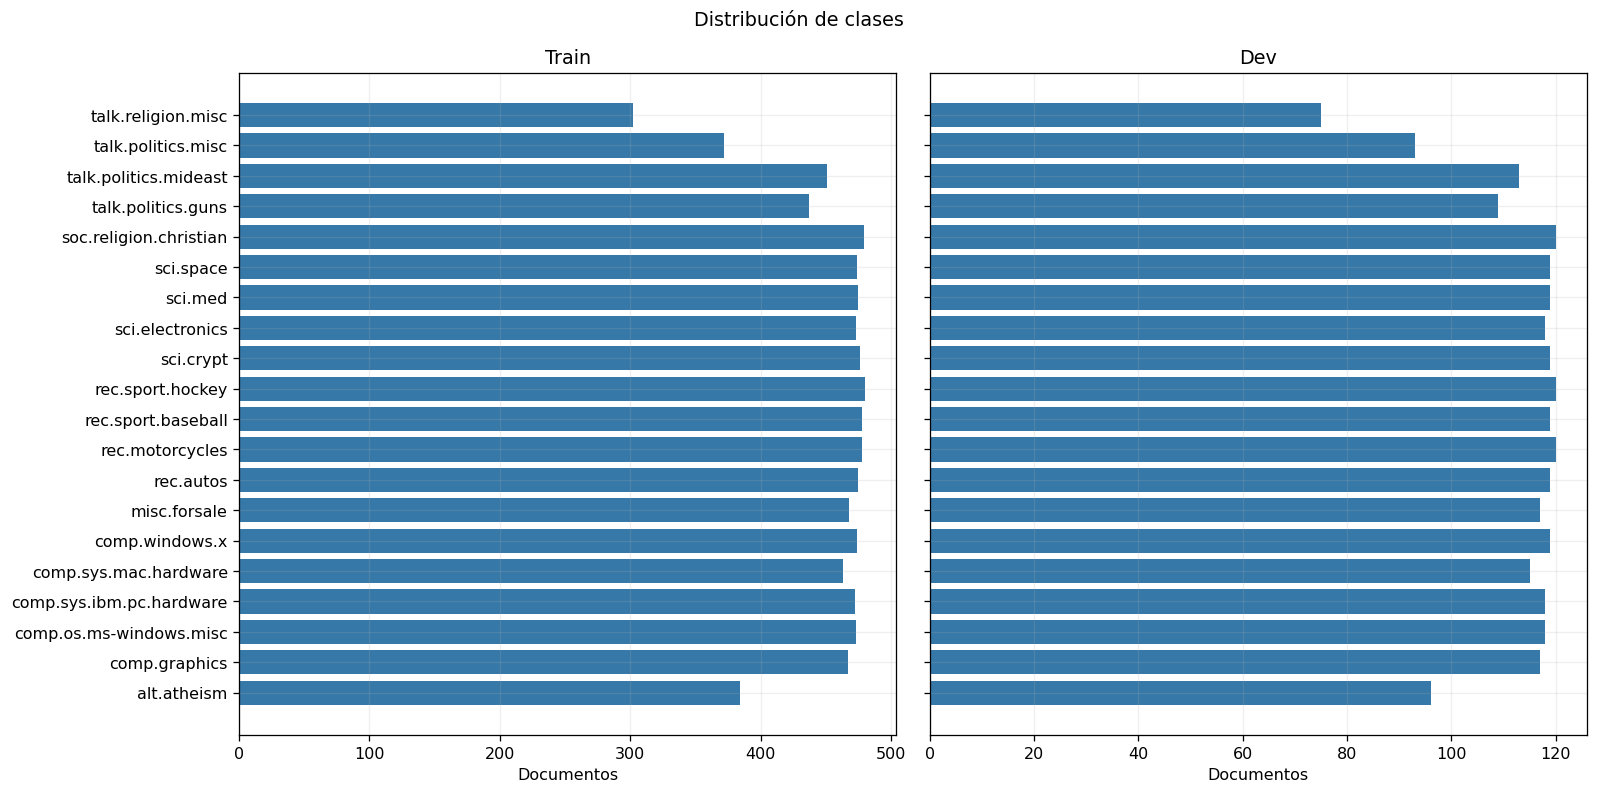

In [5]:
distributionFigure, distributionAxes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for distributionAxis, labels, partitionName in zip(distributionAxes,
        [trainLabels, validationLabels], ["Train", "Dev"]):
    distributionAxis.barh(classNames, np.bincount(labels, minlength=classCount), color="#3678a8")
    distributionAxis.set_title(partitionName)
    distributionAxis.set_xlabel("Documentos")
distributionFigure.suptitle("Distribución de clases")
distributionFigure.tight_layout()
plt.show()

In [6]:
assert set(np.unique(trainLabels)) == set(np.unique(validationLabels))

## 2. Preprocesamiento configurable

Se tokeniza en minúsculas y se conservan tokens alfabéticos. La búsqueda incluye eliminación de stopwords y normalización del texto: ninguna, stemming o lematización.

In [7]:
englishStopwords = set(stopwords.words("english"))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=200000)
def normalizeToken(token, normalization):
    if normalization == "stem":
        return stemmer.stem(token)
    if normalization == "lemmatize":
        return lemmatizer.lemmatize(token)
    return token

def preprocessText(text, removeStopwords, normalization):
    tokenVector = [token for token in word_tokenize(text.lower()) if token.isalpha()]
    return " ".join(normalizeToken(token, normalization) for token in tokenVector
                    if not removeStopwords or token not in englishStopwords)

In [8]:
exampleText = "The researchers were studying the running processes and stopping conditions of the engines."
for normalization in ["none", "stem", "lemmatize"]:
    for removeStopwords in [False, True]:
        processedExample = preprocessText(exampleText, removeStopwords, normalization)
        assert processedExample and isinstance(processedExample, str)
        print(normalization, removeStopwords, ":", processedExample)

none False : the researchers were studying the running processes and stopping conditions of the engines
none True : researchers studying running processes stopping conditions engines
stem False : the research were studi the run process and stop condit of the engin
stem True : research studi run process stop condit engin
lemmatize False : the researcher were studying the running process and stopping condition of the engine
lemmatize True : researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

Se buscan unigramas o unigramas y bigramas, un máximo de 2.000/5.000/10.000 features y min_df de 1/2/5. El vocabulario y los valores IDF se ajustan exclusivamente con train.

In [9]:
def vectorizeDocuments(trainDocuments, validationDocuments, ngramRange, maxFeatures, minDocumentFrequency):
    vectorizer = TfidfVectorizer(ngram_range=ngramRange, max_features=maxFeatures,
                                min_df=minDocumentFrequency, dtype=np.float32)
    trainFeatures = vectorizer.fit_transform(trainDocuments)
    validationFeatures = vectorizer.transform(validationDocuments)
    return trainFeatures, validationFeatures, vectorizer

In [10]:
sampleTrainFeatures, sampleValidationFeatures, sampleVectorizer = vectorizeDocuments(
    ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"],
    ["the dog sat on the mat"], (1, 1), 50, 1)
assert sampleTrainFeatures.shape[0] == 3 and sampleValidationFeatures.shape[0] == 1
print("Sanity check TF-IDF:", sampleTrainFeatures.shape, sampleValidationFeatures.shape)

Sanity check TF-IDF: (3, 13) (1, 13)


### 3.1. Normalización numérica

StandardScaler se ajusta con train y se aplica sin reajustar a dev. Se utilizan matrices densas float32, como en el TP de Softmax.

In [11]:
def normalizeFeatures(trainSparseFeatures, validationSparseFeatures):
    trainFeatures = trainSparseFeatures.toarray().astype(np.float32, copy=False)
    validationFeatures = validationSparseFeatures.toarray().astype(np.float32, copy=False)
    featureScaler = StandardScaler(copy=False)
    return featureScaler.fit_transform(trainFeatures), featureScaler.transform(validationFeatures), featureScaler

In [12]:
sampleTrainNormalized, sampleValidationNormalized, sampleScaler = normalizeFeatures(
    sampleTrainFeatures, sampleValidationFeatures)
assert np.allclose(sampleTrainNormalized.mean(axis=0), 0, atol=1e-6)
assert np.allclose(sampleTrainNormalized.std(axis=0), 1, atol=1e-6)
assert np.isfinite(sampleValidationNormalized).all()
display(pd.DataFrame(sampleTrainNormalized, columns=sampleVectorizer.get_feature_names_out()))

,and,are,cat,cats,dogs,in,mat,on,park,pets,running,sat,the
0,-0.707107,-1.411970,1.414214,-0.707107,-1.411970,-0.707107,1.414214,1.414214,-0.707107,-0.707107,-0.707107,1.414214,1.156983
1,-0.707107,0.637029,-0.707107,-0.707107,0.637029,1.414214,-0.707107,-0.707107,1.414214,-0.707107,1.414214,-0.707107,0.125812
2,1.414214,0.774942,-0.707107,1.414214,0.774942,-0.707107,-0.707107,-0.707107,-0.707107,1.414214,-0.707107,-0.707107,-1.282795


## 4. Modelos: MLP y regresión Softmax

El MLP admite de una a tres capas ocultas, con ancho independiente entre 2 y 512 neuronas en potencias de dos. Una misma activación se aplica a todas las capas ocultas. La inicialización es Kaiming para ReLU/LeakyReLU y Xavier para Tanh/ELU; LeakyReLU utiliza pendiente negativa 0,01.

La regresión Softmax contiene una única capa lineal y no tiene capas ocultas ni activaciones intermedias. Su matriz se inicializa con Xavier. Ambos modelos devuelven 20 logits, sin Softmax explícita antes de CrossEntropyLoss, y sus bias comienzan en cero. La semilla se reinicia antes de construir cada modelo.

Los modelos seleccionados se guardan mediante sus pesos y metadatos, junto con el vectorizador TF-IDF y el scaler ajustados con train. Los mismos archivos se registran como artefactos de MLflow.

In [13]:
class TextMLP(nn.Module):
    def __init__(self, inputDimension, outputClasses, hiddenWidths, activationName):
        super().__init__()
        activationFactories = {"Tanh": nn.Tanh, "ELU": nn.ELU, "ReLU": nn.ReLU,
                               "LeakyReLU": lambda: nn.LeakyReLU(0.01)}
        networkLayers = OrderedDict()
        previousWidth = inputDimension
        for layerIndex, hiddenWidth in enumerate(hiddenWidths, start=1):
            hiddenLayer = nn.Linear(previousWidth, hiddenWidth)
            if activationName in ["ReLU", "LeakyReLU"]:
                nn.init.kaiming_uniform_(hiddenLayer.weight, a=0.01 if activationName == "LeakyReLU" else 0,
                    nonlinearity="leaky_relu" if activationName == "LeakyReLU" else "relu")
            else:
                layerGain = nn.init.calculate_gain("tanh") if activationName == "Tanh" else 1.0
                nn.init.xavier_uniform_(hiddenLayer.weight, gain=layerGain)
            nn.init.zeros_(hiddenLayer.bias)
            networkLayers[f"hiddenLayer{layerIndex}"] = hiddenLayer
            networkLayers[f"activation{layerIndex}"] = activationFactories[activationName]()
            previousWidth = hiddenWidth
        outputLayer = nn.Linear(previousWidth, outputClasses)
        nn.init.xavier_uniform_(outputLayer.weight)
        nn.init.zeros_(outputLayer.bias)
        networkLayers["outputLayer"] = outputLayer
        self.network = nn.Sequential(networkLayers)

    def forward(self, featureBatch):
        return self.network(featureBatch)

def meanAbsoluteWeights(model):
    return {parameterName: parameterTensor.detach().abs().mean().item()
            for parameterName, parameterTensor in model.named_parameters() if parameterName.endswith("weight")}

class SoftmaxRegression(nn.Module):
    def __init__(self, inputDimension, outputClasses):
        super().__init__()
        self.outputLayer = nn.Linear(inputDimension, outputClasses)
        nn.init.xavier_uniform_(self.outputLayer.weight)
        nn.init.zeros_(self.outputLayer.bias)

    def forward(self, featureBatch):
        return self.outputLayer(featureBatch)

def createTextModel(modelFamily, inputDimension, outputClasses, parameters):
    if modelFamily == "MLP":
        return TextMLP(inputDimension, outputClasses, parameters["hiddenWidths"], parameters["activationName"])
    if modelFamily == "Softmax":
        return SoftmaxRegression(inputDimension, outputClasses)
    raise ValueError(f"Familia desconocida: {modelFamily}")

def loadSelectedModel(modelFamily):
    checkpoint = torch.load(modelDirectory / f"{modelFamily}.pt", map_location="cpu", weights_only=True)
    preprocessing = joblib.load(modelDirectory / f"{modelFamily}_preprocesamiento.joblib")
    assert checkpoint["checkpointId"] == preprocessing["checkpointId"]
    restoredModel = createTextModel(checkpoint["modelFamily"], checkpoint["inputDimension"],
                                   len(checkpoint["classNames"]), checkpoint["parameters"])
    restoredModel.load_state_dict(checkpoint["modelState"])
    restoredModel.eval()
    return {**preprocessing, **{key: value for key, value in checkpoint.items() if key != "modelState"},
            "model": restoredModel}

def saveSelectedModel(modelFamily, modelBundle):
    modelDirectory.mkdir(exist_ok=True)
    checkpointId = f"{studyLabel}_{modelFamily}_trial_{modelBundle['trial']}"
    checkpointPath = modelDirectory / f"{modelFamily}.pt"
    preprocessingPath = modelDirectory / f"{modelFamily}_preprocesamiento.joblib"
    checkpoint = {"checkpointId": checkpointId, "modelFamily": modelFamily,
        "inputDimension": modelBundle["inputDimension"], "classNames": list(classNames),
        "parameters": modelBundle["parameters"], "trial": modelBundle["trial"],
        "validationAccuracy": float(modelBundle["validationAccuracy"]), "seed": SEED, "epochs": EPOCH_COUNT,
        "modelState": {name: weights.detach().cpu() for name, weights in modelBundle["model"].state_dict().items()}}
    torch.save(checkpoint, checkpointPath)
    joblib.dump({"checkpointId": checkpointId, "vectorizer": modelBundle["vectorizer"],
        "scaler": modelBundle["scaler"], "validationPredictions": modelBundle["validationPredictions"]}, preprocessingPath)
    restoredBundle = loadSelectedModel(modelFamily)
    textDocuments = processedDocuments(modelBundle["parameters"]["removeStopwords"],
                                       modelBundle["parameters"]["textNormalization"])
    verificationDocuments = [textDocuments[documentIndex] for documentIndex in validationIndices]
    verificationFeatures = restoredBundle["vectorizer"].transform(verificationDocuments).toarray().astype(np.float32)
    verificationFeatures = restoredBundle["scaler"].transform(verificationFeatures)
    verificationLoader = DataLoader(TensorDataset(torch.from_numpy(verificationFeatures),
        torch.as_tensor(validationLabels, dtype=torch.long)), batch_size=512, shuffle=False)
    restoredPredictions = predictModel(restoredBundle["model"], verificationLoader)
    assert np.array_equal(restoredPredictions, modelBundle["validationPredictions"])
    assert np.isclose(accuracy_score(validationLabels, restoredPredictions), modelBundle["validationAccuracy"])
    with mlflow.start_run(run_name=f"{studyLabel}_{modelFamily}_modelo_guardado"):
        mlflow.set_tags({"study": studyLabel, "modelFamily": modelFamily, "checkpointId": checkpointId})
        mlflow.log_params(modelBundle["parameters"])
        mlflow.log_metrics({"validationAccuracy": modelBundle["validationAccuracy"], "reloadVerified": 1.0})
        mlflow.log_artifact(str(checkpointPath), artifact_path="modelo")
        mlflow.log_artifact(str(preprocessingPath), artifact_path="modelo")
    print(f"{modelFamily}: pesos y preprocesamiento guardados; recarga verificada sobre {len(validationLabels)} documentos de dev.")
    return {"checkpoint": checkpointPath, "preprocessing": preprocessingPath}

In [14]:
for hiddenWidths in [[32], [32, 16], [32, 16, 8]]:
    for activationName in ["Tanh", "ELU", "ReLU", "LeakyReLU"]:
        sampleModel = TextMLP(50, 20, hiddenWidths, activationName)
        sampleLogits = sampleModel(torch.randn(4, 50))
        assert sampleLogits.shape == (4, 20) and torch.isfinite(sampleLogits).all()
        nn.CrossEntropyLoss()(sampleLogits, torch.tensor([0, 1, 2, 3])).backward()
        assert all(parameter.grad is not None and torch.isfinite(parameter.grad).all()
                   for parameter in sampleModel.parameters())
sampleSoftmax = SoftmaxRegression(50, 20)
sampleSoftmaxLogits = sampleSoftmax(torch.randn(4, 50))
assert sampleSoftmaxLogits.shape == (4, 20) and torch.isfinite(sampleSoftmaxLogits).all()
nn.CrossEntropyLoss()(sampleSoftmaxLogits, torch.tensor([0, 1, 2, 3])).backward()
assert all(parameter.grad is not None and torch.isfinite(parameter.grad).all()
           for parameter in sampleSoftmax.parameters())
setRandomSeeds()
print("Sanity checks de dimensiones y gradientes: correctos")

Sanity checks de dimensiones y gradientes: correctos


## 5. Entrenamiento

Se registra accuracy y loss de train/dev al finalizar cada época, en modo evaluación y con los mismos pesos. Los batches de train se mezclan con un generador de semilla fija; dev mantiene su orden. Se registran también la OFM, los tiempos y la media de abs(pesos) por capa, excluyendo bias. No se aplica regularización ni early stopping adicional.

In [15]:
def evaluateModel(model, evaluationLoader):
    model.eval()
    lossFunction = nn.CrossEntropyLoss()
    totalLoss, correctPredictions, documentCount = 0.0, 0, 0
    with torch.no_grad():
        for featureBatch, labelBatch in evaluationLoader:
            batchLogits = model(featureBatch)
            batchLoss = lossFunction(batchLogits, labelBatch)
            if not torch.isfinite(batchLoss):
                raise FloatingPointError("Loss no finita en evaluación")
            totalLoss += batchLoss.item() * len(labelBatch)
            correctPredictions += (batchLogits.argmax(dim=1) == labelBatch).sum().item()
            documentCount += len(labelBatch)
    return totalLoss/documentCount, correctPredictions/documentCount

def recordWeightHistograms(model, writer, epochNumber):
    for parameterName, parameterTensor in model.named_parameters():
        if parameterName.endswith("weight"):
            writer.add_histogram(parameterName, parameterTensor.detach(), epochNumber)

def predictModel(model, evaluationLoader):
    model.eval()
    with torch.no_grad():
        return np.concatenate([model(featureBatch).argmax(dim=1).cpu().numpy()
                               for featureBatch, labelBatch in evaluationLoader])

In [16]:
def trainModel(model, trainLoader, trainEvaluationLoader, validationLoader, optimizer, trial, writer, record):
    lossFunction = nn.CrossEntropyLoss()
    record["weightHistory"].append({"epoch": 0, **meanAbsoluteWeights(model)})
    recordWeightHistograms(model, writer, 0)
    for epochNumber in range(1, EPOCH_COUNT+1):
        epochStart = time.perf_counter()
        model.train()
        for featureBatch, labelBatch in trainLoader:
            optimizer.zero_grad(set_to_none=True)
            batchLogits = model(featureBatch)
            batchLoss = lossFunction(batchLogits, labelBatch)
            if not torch.isfinite(batchLoss):
                raise FloatingPointError("Loss no finita durante entrenamiento")
            batchLoss.backward()
            optimizer.step()
        trainLoss, trainAccuracy = evaluateModel(model, trainEvaluationLoader)
        validationLoss, validationAccuracy = evaluateModel(model, validationLoader)
        epochMetrics = {"epoch": epochNumber, "trainLoss": trainLoss, "validationLoss": validationLoss,
            "trainAccuracy": trainAccuracy, "validationAccuracy": validationAccuracy,
            "accuracyGap": trainAccuracy-validationAccuracy, "epochSeconds": time.perf_counter()-epochStart}
        record["history"].append(epochMetrics)
        currentWeightStatistics = meanAbsoluteWeights(model)
        record["weightHistory"].append({"epoch": epochNumber, **currentWeightStatistics})
        mlflow.log_metrics({metricName: metricValue for metricName, metricValue in epochMetrics.items()
                            if metricName != "epoch"}, step=epochNumber)
        for metricName, metricValue in epochMetrics.items():
            if metricName != "epoch":
                writer.add_scalar(metricName, metricValue, epochNumber)
        for parameterName, meanAbsoluteWeight in currentWeightStatistics.items():
            writer.add_scalar(f"meanAbsoluteWeight/{parameterName}", meanAbsoluteWeight, epochNumber)
            mlflow.log_metric("meanAbs_"+parameterName.replace(".", "_"), meanAbsoluteWeight, step=epochNumber)
        writer.flush()
        trial.report(validationAccuracy, step=epochNumber)
        if trial.should_prune():
            raise optuna.TrialPruned(f"Accuracy de dev poco competitiva en época {epochNumber}")
    recordWeightHistograms(model, writer, EPOCH_COUNT)
    return record["history"][-1]["validationAccuracy"]

## 6. Búsqueda de hiperparámetros con Optuna

Se realizan dos estudios independientes: 100 trials para MLP y 100 para Softmax. Ambos usan TPESampler con semilla 42, diez propuestas iniciales aleatorias y learning rate logarítmico entre 0,0001 y 0,1. Comparten las opciones de preprocesamiento, batch size y optimizador; solo el MLP busca arquitectura y activación.

MedianPruner completa los primeros diez trials de cada estudio. Los posteriores alcanzan al menos la época 3 antes de poder podarse y requieren cinco referencias para evaluar la poda. Cada trial completo tiene cinco épocas. La selección utiliza su accuracy final de dev. Los podados se identifican como observaciones parciales y se excluyen de los promedios de desempeño final y de la selección del mayor OFM entre entrenamientos completos.

In [17]:
tokenCachePath = projectDirectory / ".experimentos" / "tokens_train_oficial.joblib"
if tokenCachePath.exists():
    tokenizedDocuments = joblib.load(tokenCachePath)
else:
    tokenizedDocuments = [[token for token in word_tokenize(document.lower()) if token.isalpha()]
                          for document in officialTrainDataset.data]
assert len(tokenizedDocuments) == len(officialTrainDataset.data)
processedTextCache = {}

def processedDocuments(removeStopwords, normalization):
    cacheKey = (removeStopwords, normalization)
    if cacheKey not in processedTextCache:
        processedTextCache[cacheKey] = [" ".join(normalizeToken(token, normalization) for token in tokenVector
            if not removeStopwords or token not in englishStopwords) for tokenVector in tokenizedDocuments]
    return processedTextCache[cacheKey]

def sampleHyperparameters(trial, modelFamily):
    parameters = {
        "removeStopwords": trial.suggest_categorical("removeStopwords", [False, True]),
        "textNormalization": trial.suggest_categorical("textNormalization", ["none", "lemmatize", "stem"]),
        "ngramMaximum": trial.suggest_categorical("ngramMaximum", [1, 2]),
        "maxFeatures": trial.suggest_categorical("maxFeatures", [2000, 5000, 10000]),
        "minDocumentFrequency": trial.suggest_categorical("minDocumentFrequency", [1, 2, 5]),
        "learningRate": trial.suggest_float("learningRate", 0.0001, 0.1, log=True),
        "batchSize": trial.suggest_categorical("batchSize", [32, 64, 128, 256, 512]),
    }
    parameters.update(hiddenLayerCount=0, hiddenWidths=[], activationName="Lineal")
    if modelFamily == "MLP":
        parameters["hiddenLayerCount"] = trial.suggest_categorical("hiddenLayerCount", [1, 2, 3])
        parameters["hiddenWidths"] = [trial.suggest_categorical(f"hiddenWidth{layerIndex+1}",
            [2, 4, 8, 16, 32, 64, 128, 256, 512]) for layerIndex in range(parameters["hiddenLayerCount"])]
        parameters["activationName"] = trial.suggest_categorical("activationName", ["Tanh", "ELU", "ReLU", "LeakyReLU"])
    parameters["optimizerName"] = trial.suggest_categorical("optimizerName", ["Adam", "RMSprop", "SGD"])
    if parameters["optimizerName"] == "Adam":
        parameters["beta1"] = trial.suggest_categorical("beta1", [0.9, 0.95])
        parameters["beta2"] = trial.suggest_categorical("beta2", [0.99, 0.999])
    elif parameters["optimizerName"] == "RMSprop":
        parameters["alpha"] = trial.suggest_categorical("alpha", [0.9, 0.99])
        parameters["momentum"] = trial.suggest_categorical("rmsMomentum", [0.0, 0.9])
    else:
        parameters["momentum"] = trial.suggest_categorical("sgdMomentum", [0.0, 0.9])
    return parameters

def createOptimizer(model, parameters):
    if parameters["optimizerName"] == "Adam":
        return torch.optim.Adam(model.parameters(), lr=parameters["learningRate"],
                                betas=(parameters["beta1"], parameters["beta2"]))
    if parameters["optimizerName"] == "RMSprop":
        return torch.optim.RMSprop(model.parameters(), lr=parameters["learningRate"],
                                  alpha=parameters["alpha"], momentum=parameters["momentum"])
    return torch.optim.SGD(model.parameters(), lr=parameters["learningRate"], momentum=parameters["momentum"])

In [18]:
def runModelSearch(modelFamily, trialCount):
    trainingRecords = {}
    bestModelBundle = {"validationAccuracy": -1.0}
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction="maximize", study_name=f"{studyLabel}_{modelFamily}",
        sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=3, interval_steps=1, n_min_trials=5))

    def objective(trial):
        trialStart = time.perf_counter()
        parameters = sampleHyperparameters(trial, modelFamily)
        setRandomSeeds()
        textDocuments = processedDocuments(parameters["removeStopwords"], parameters["textNormalization"])
        trainDocuments = [textDocuments[documentIndex] for documentIndex in trainIndices]
        validationDocuments = [textDocuments[documentIndex] for documentIndex in validationIndices]
        trainSparseFeatures, validationSparseFeatures, vectorizer = vectorizeDocuments(trainDocuments, validationDocuments,
            (1, parameters["ngramMaximum"]), parameters["maxFeatures"], parameters["minDocumentFrequency"])
        trainFeatures, validationFeatures, featureScaler = normalizeFeatures(trainSparseFeatures, validationSparseFeatures)
        trainDataset = TensorDataset(torch.from_numpy(trainFeatures), torch.as_tensor(trainLabels, dtype=torch.long))
        validationDataset = TensorDataset(torch.from_numpy(validationFeatures), torch.as_tensor(validationLabels, dtype=torch.long))
        trainLoader = DataLoader(trainDataset, batch_size=parameters["batchSize"], shuffle=True,
            generator=torch.Generator().manual_seed(SEED), num_workers=0)
        trainEvaluationLoader = DataLoader(trainDataset, batch_size=512, shuffle=False)
        validationLoader = DataLoader(validationDataset, batch_size=512, shuffle=False)
        model = createTextModel(modelFamily, trainFeatures.shape[1], classCount, parameters)
        optimizer = createOptimizer(model, parameters)
        record = {"parameters": parameters, "history": [], "weightHistory": [], "state": "RUNNING",
                  "parameterCount": sum(parameter.numel() for parameter in model.parameters()),
                  "preparationSeconds": time.perf_counter()-trialStart}
        trainingRecords[trial.number] = record
        writer = SummaryWriter(str(tensorboardDirectory / modelFamily / f"trial_{trial.number:03d}"))
        trackingRun = mlflow.start_run(run_name=f"{studyLabel}_{modelFamily}_trial_{trial.number:03d}")
        mlflow.set_tags({"study": studyLabel, "sampler": "TPE", "trial": str(trial.number), "modelFamily": modelFamily})
        mlflow.log_params({**parameters, "seed": SEED, "maxEpochs": EPOCH_COUNT,
                          "parameterCount": record["parameterCount"], "pruning": "MedianPruner"})
        trackingStatus = "FINISHED"
        trainingStart = time.perf_counter()
        try:
            finalValidationAccuracy = trainModel(model, trainLoader, trainEvaluationLoader, validationLoader,
                                                optimizer, trial, writer, record)
            record["state"] = "COMPLETE"
            if finalValidationAccuracy > bestModelBundle["validationAccuracy"]:
                model.eval()
                with torch.no_grad():
                    validationPredictions = np.concatenate([model(featureBatch).argmax(dim=1).numpy()
                                                           for featureBatch, labelBatch in validationLoader])
                bestModelBundle.update(validationAccuracy=finalValidationAccuracy, trial=trial.number,
                    modelFamily=modelFamily, inputDimension=trainFeatures.shape[1],
                    model=copy.deepcopy(model), vectorizer=vectorizer, scaler=featureScaler,
                    parameters=parameters.copy(), validationPredictions=validationPredictions)
            return finalValidationAccuracy
        except optuna.TrialPruned:
            record["state"] = "PRUNED"
            trackingStatus = "KILLED"
            raise
        except Exception:
            record["state"] = "FAIL"
            trackingStatus = "FAILED"
            raise
        finally:
            record["trainingSeconds"] = time.perf_counter()-trainingStart
            record["totalSeconds"] = time.perf_counter()-trialStart
            record["finalWeightSamples"] = {parameterName: parameterTensor.detach().flatten()[::max(1, parameterTensor.numel()//10000)].tolist()
                for parameterName, parameterTensor in model.named_parameters() if parameterName.endswith("weight")}
            mlflow.set_tag("trialState", record["state"])
            mlflow.log_metrics({"trainingSeconds": record["trainingSeconds"], "totalSeconds": record["totalSeconds"],
                                "epochsExecuted": len(record["history"])})
            mlflow.end_run(status=trackingStatus)
            writer.close()
            finalDev = record["history"][-1]["validationAccuracy"] if record["history"] else float("nan")
            print(f"{modelFamily} | Trial {trial.number:03d} | {record['state']} | épocas {len(record['history'])} | dev {finalDev:.2%}", flush=True)
            del model, optimizer, trainDataset, validationDataset, trainLoader, trainEvaluationLoader, validationLoader
            del trainFeatures, validationFeatures, trainSparseFeatures, validationSparseFeatures
            gc.collect()

    searchStart = time.perf_counter()
    study.optimize(objective, n_trials=trialCount, n_jobs=1, catch=(FloatingPointError,))
    searchSeconds = time.perf_counter()-searchStart
    assert all((1 <= record["parameters"]["hiddenLayerCount"] <= 3) if modelFamily == "MLP"
               else record["parameters"]["hiddenLayerCount"] == 0 for record in trainingRecords.values())
    print(f"Búsqueda terminada en {searchSeconds/60:.1f} minutos")
    bestModelBundle["savedFiles"] = saveSelectedModel(modelFamily, bestModelBundle)
    return study, trainingRecords, bestModelBundle, searchSeconds


study, trainingRecords, bestModelBundle, searchSeconds = runModelSearch("MLP", MLP_TRIAL_COUNT)

MLP | Trial 000 | COMPLETE | épocas 5 | dev 50.46%
MLP | Trial 001 | COMPLETE | épocas 5 | dev 5.83%
MLP | Trial 002 | COMPLETE | épocas 5 | dev 48.34%
MLP | Trial 003 | COMPLETE | épocas 5 | dev 52.89%
MLP | Trial 004 | COMPLETE | épocas 5 | dev 51.17%
MLP | Trial 005 | COMPLETE | épocas 5 | dev 5.17%
MLP | Trial 006 | COMPLETE | épocas 5 | dev 13.43%
MLP | Trial 007 | COMPLETE | épocas 5 | dev 58.73%
MLP | Trial 008 | COMPLETE | épocas 5 | dev 49.01%
MLP | Trial 009 | COMPLETE | épocas 5 | dev 49.14%
MLP | Trial 010 | PRUNED | épocas 3 | dev 4.24%
MLP | Trial 011 | PRUNED | épocas 3 | dev 37.43%
MLP | Trial 012 | PRUNED | épocas 3 | dev 45.38%
MLP | Trial 013 | COMPLETE | épocas 5 | dev 66.55%
MLP | Trial 014 | COMPLETE | épocas 5 | dev 65.36%
MLP | Trial 015 | COMPLETE | épocas 5 | dev 65.40%
MLP | Trial 016 | PRUNED | épocas 3 | dev 8.62%
MLP | Trial 017 | COMPLETE | épocas 5 | dev 64.25%
MLP | Trial 018 | COMPLETE | épocas 5 | dev 63.01%
MLP | Trial 019 | COMPLETE | épocas 5 | dev

Completos: 49 | Podados: 51 | Fallidos: 0
Épocas ejecutadas: 398 | Épocas omitidas por pruning: 102


,modelFamily,trial,state,epochs,hiddenLayerCount,hiddenWidths,activation,optimizer,learningRate,trainAccuracy,validationAccuracy,maximumGap,maximumGapEpoch,totalSeconds,trainingSeconds
19,MLP,19,COMPLETE,5,1,[256],ReLU,Adam,0.00245,97.26%,68.23%,29.52%,4,8.193038,6.071840
68,MLP,68,COMPLETE,5,1,[256],LeakyReLU,Adam,0.00116,97.36%,68.01%,29.35%,5,8.121541,6.492802
76,MLP,76,COMPLETE,5,1,[256],Tanh,Adam,0.00414,97.24%,68.01%,29.50%,3,4.906045,3.691803
85,MLP,85,COMPLETE,5,1,[256],LeakyReLU,Adam,0.00112,97.36%,67.96%,29.40%,5,9.015739,7.327399
69,MLP,69,COMPLETE,5,1,[256],LeakyReLU,Adam,0.00105,97.36%,67.87%,29.48%,5,8.299889,6.407850
70,MLP,70,COMPLETE,5,1,[256],LeakyReLU,Adam,0.00071,97.34%,67.79%,29.63%,4,7.998000,6.261052
65,MLP,65,COMPLETE,5,1,[256],LeakyReLU,Adam,0.00147,97.26%,67.79%,29.47%,5,4.959548,3.746898
42,MLP,42,COMPLETE,5,1,[256],LeakyReLU,Adam,0.00109,97.25%,67.70%,29.64%,4,4.277262,3.213825
25,MLP,25,COMPLETE,5,1,[512],ReLU,Adam,0.00092,97.45%,67.70%,29.87%,2,7.396742,6.000771
92,MLP,92,COMPLETE,5,1,[512],ReLU,Adam,0.00223,97.25%,67.48%,30.84%,2,8.635317,7.168775


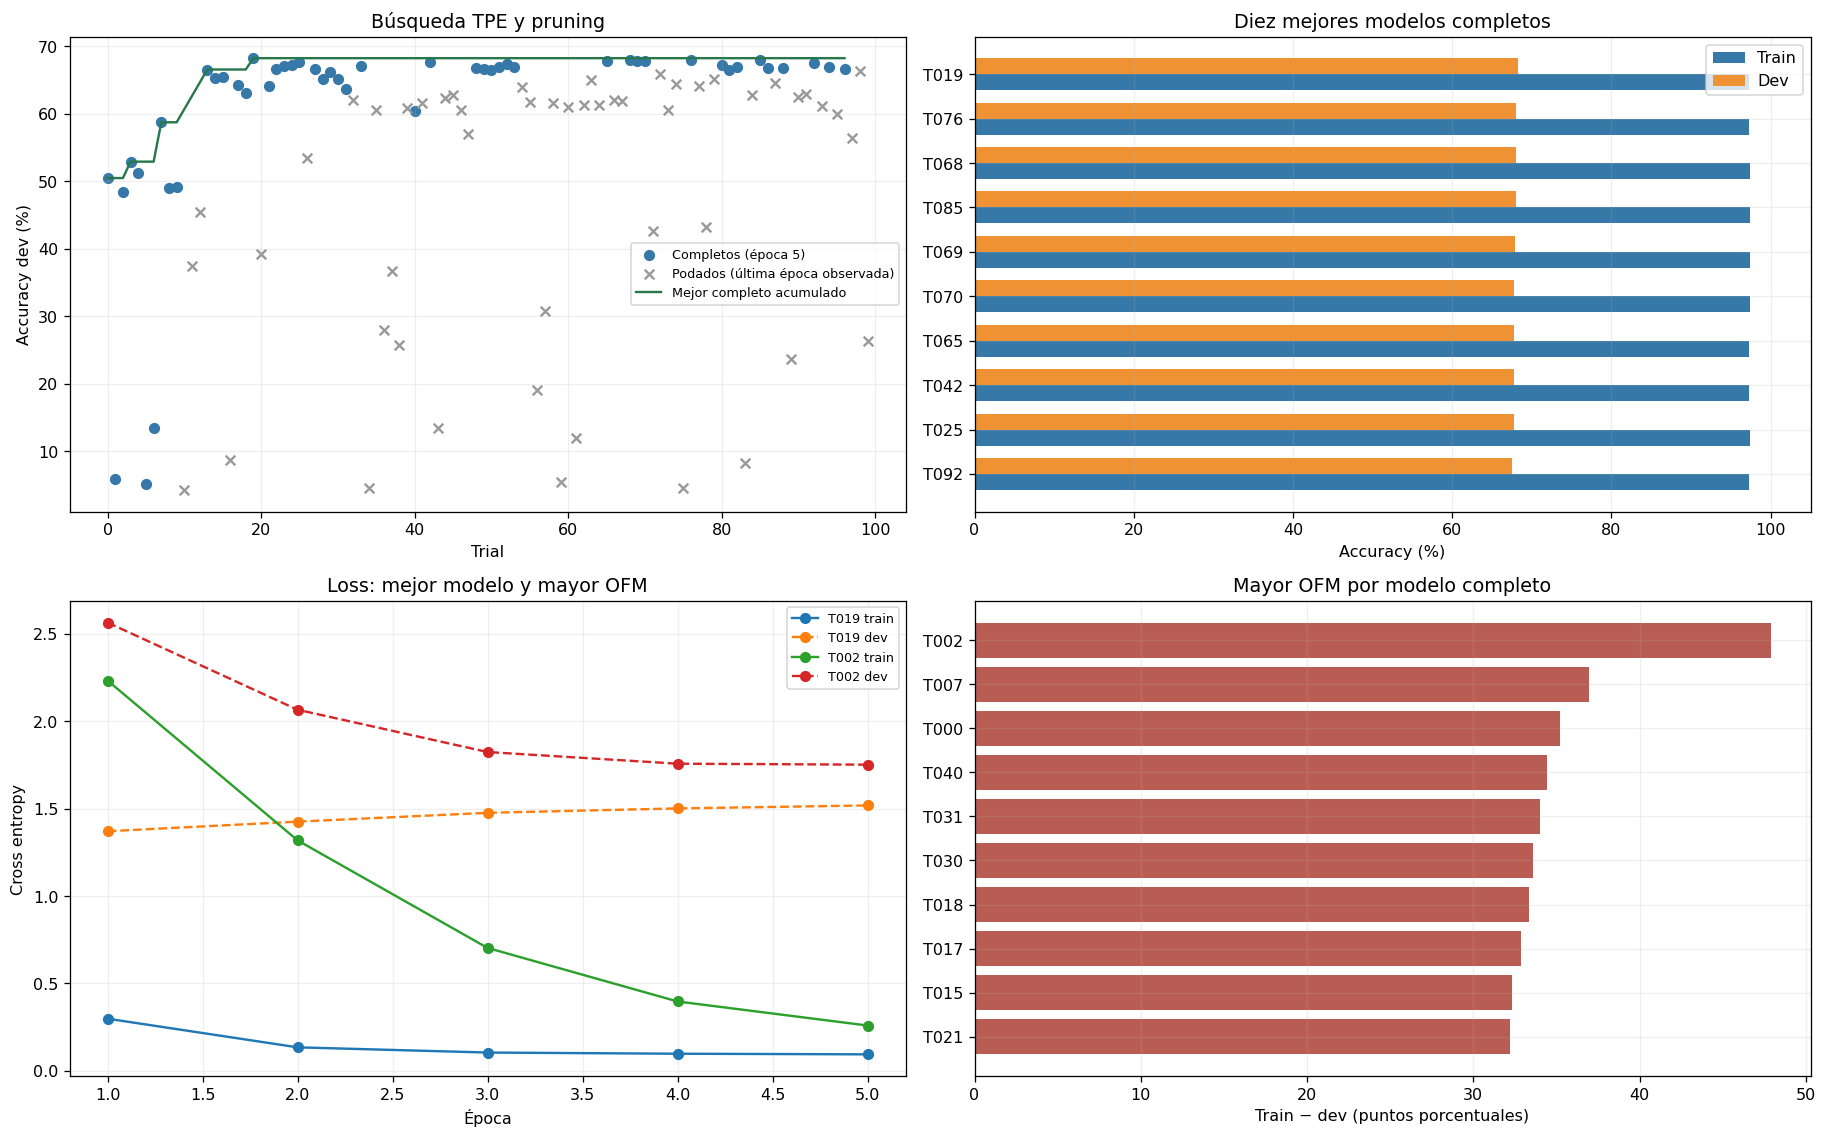

In [19]:
def summarizeTrainingRecords(modelFamily, records):
    summaryRows = []
    for trialNumber, record in records.items():
        lastEpoch = record["history"][-1] if record["history"] else {}
        maximumGapEpoch = max(record["history"], key=lambda epochMetrics: epochMetrics["accuracyGap"],
                              default={"accuracyGap": np.nan, "epoch": 0})
        parameters = record["parameters"]
        summaryRows.append({"modelFamily": modelFamily, "trial": trialNumber, "state": record["state"],
            "epochs": len(record["history"]), "hiddenLayerCount": parameters["hiddenLayerCount"],
            "hiddenWidths": str(parameters["hiddenWidths"]), "activation": parameters["activationName"],
            "optimizer": parameters["optimizerName"], "learningRate": parameters["learningRate"],
            "trainAccuracy": lastEpoch.get("trainAccuracy", np.nan), "validationAccuracy": lastEpoch.get("validationAccuracy", np.nan),
            "maximumGap": maximumGapEpoch["accuracyGap"], "maximumGapEpoch": maximumGapEpoch["epoch"],
            "totalSeconds": record["totalSeconds"], "trainingSeconds": record["trainingSeconds"]})
    return pd.DataFrame(summaryRows)

summaryTable = summarizeTrainingRecords("MLP", trainingRecords)
completedTable = summaryTable[summaryTable.state == "COMPLETE"].copy()
prunedTable = summaryTable[summaryTable.state == "PRUNED"].copy()
bestTrialNumber = int(completedTable.loc[completedTable.validationAccuracy.idxmax(), "trial"])
maximumGapTrialNumber = int(completedTable.loc[completedTable.maximumGap.idxmax(), "trial"])
executedEpochs = sum(len(record["history"]) for record in trainingRecords.values())
omittedEpochs = sum(EPOCH_COUNT-len(record["history"]) for record in trainingRecords.values() if record["state"] == "PRUNED")
print(f"Completos: {len(completedTable)} | Podados: {len(prunedTable)} | Fallidos: {sum(record['state']=='FAIL' for record in trainingRecords.values())}")
print(f"Épocas ejecutadas: {executedEpochs} | Épocas omitidas por pruning: {omittedEpochs}")
display(completedTable.sort_values("validationAccuracy", ascending=False).head(10).style.format({
    "trainAccuracy": "{:.2%}", "validationAccuracy": "{:.2%}", "maximumGap": "{:.2%}", "learningRate": "{:.5f}"}))

comparisonFigure, comparisonAxes = plt.subplots(2, 2, figsize=(16, 10))
searchAxis, accuracyAxis, lossAxis, gapAxis = comparisonAxes.flat
searchAxis.scatter(completedTable.trial, 100*completedTable.validationAccuracy, label="Completos (época 5)", color="#3678a8")
searchAxis.scatter(prunedTable.trial, 100*prunedTable.validationAccuracy, label="Podados (última época observada)", marker="x", color="#999999")
completeInOrder = completedTable.sort_values("trial")
searchAxis.plot(completeInOrder.trial, 100*completeInOrder.validationAccuracy.cummax(), color="#28784b", label="Mejor completo acumulado")
searchAxis.set(title="Búsqueda TPE y pruning", xlabel="Trial", ylabel="Accuracy dev (%)")
searchAxis.legend(fontsize=8)
topTable = completedTable.nlargest(10, "validationAccuracy").sort_values("validationAccuracy")
topPositions = np.arange(len(topTable))
accuracyAxis.barh(topPositions-0.18, 100*topTable.trainAccuracy, height=0.36, label="Train", color="#3678a8")
accuracyAxis.barh(topPositions+0.18, 100*topTable.validationAccuracy, height=0.36, label="Dev", color="#ef9234")
accuracyAxis.set_yticks(topPositions, [f"T{trialNumber:03d}" for trialNumber in topTable.trial])
accuracyAxis.set(title="Diez mejores modelos completos", xlabel="Accuracy (%)", xlim=(0, 105))
accuracyAxis.legend()
for trialNumber in dict.fromkeys([bestTrialNumber, maximumGapTrialNumber]):
    historyTable = pd.DataFrame(trainingRecords[trialNumber]["history"])
    lossAxis.plot(historyTable.epoch, historyTable.trainLoss, marker="o", label=f"T{trialNumber:03d} train")
    lossAxis.plot(historyTable.epoch, historyTable.validationLoss, marker="o", linestyle="--", label=f"T{trialNumber:03d} dev")
lossAxis.set(title="Loss: mejor modelo y mayor OFM", xlabel="Época", ylabel="Cross entropy")
lossAxis.legend(fontsize=8)
gapTable = completedTable.nlargest(10, "maximumGap").sort_values("maximumGap")
gapAxis.barh([f"T{trialNumber:03d}" for trialNumber in gapTable.trial], 100*gapTable.maximumGap, color="#b95d54")
gapAxis.set(title="Mayor OFM por modelo completo", xlabel="Train − dev (puntos porcentuales)")
comparisonFigure.tight_layout()
with mlflow.start_run(run_name=f"{studyLabel}_resumen"):
    mlflow.set_tag("study", studyLabel)
    mlflow.log_params({"sampler": "TPE", "pruner": "MedianPruner", "seed": SEED, "maxEpochs": EPOCH_COUNT, "trials": MLP_TRIAL_COUNT})
    mlflow.log_metrics({"bestValidationAccuracy": study.best_value, "completedTrials": len(completedTable),
        "prunedTrials": len(prunedTable), "searchSeconds": searchSeconds, "omittedEpochs": omittedEpochs,
        "maximumCompleteAccuracyGap": float(completedTable.maximumGap.max())})
    mlflow.log_figure(comparisonFigure, "comparacion.png")
plt.show()

## 7. Modelo seleccionado y curvas de aprendizaje

Se conserva el modelo del trial completo con mayor accuracy final de dev. La comparación de curvas utiliza los mismos pesos al evaluar train y dev. Los trials podados se identifican como observaciones parciales y no se consideran candidatos finales.

Hiperparámetros seleccionados: {'removeStopwords': True, 'textNormalization': 'stem', 'ngramMaximum': 1, 'maxFeatures': 5000, 'minDocumentFrequency': 1, 'learningRate': 0.0024524713668806378, 'batchSize': 512, 'hiddenLayerCount': 1, 'hiddenWidths': [256], 'activationName': 'ReLU', 'optimizerName': 'Adam', 'beta1': 0.9, 'beta2': 0.999}
Accuracy dev: 68.23%


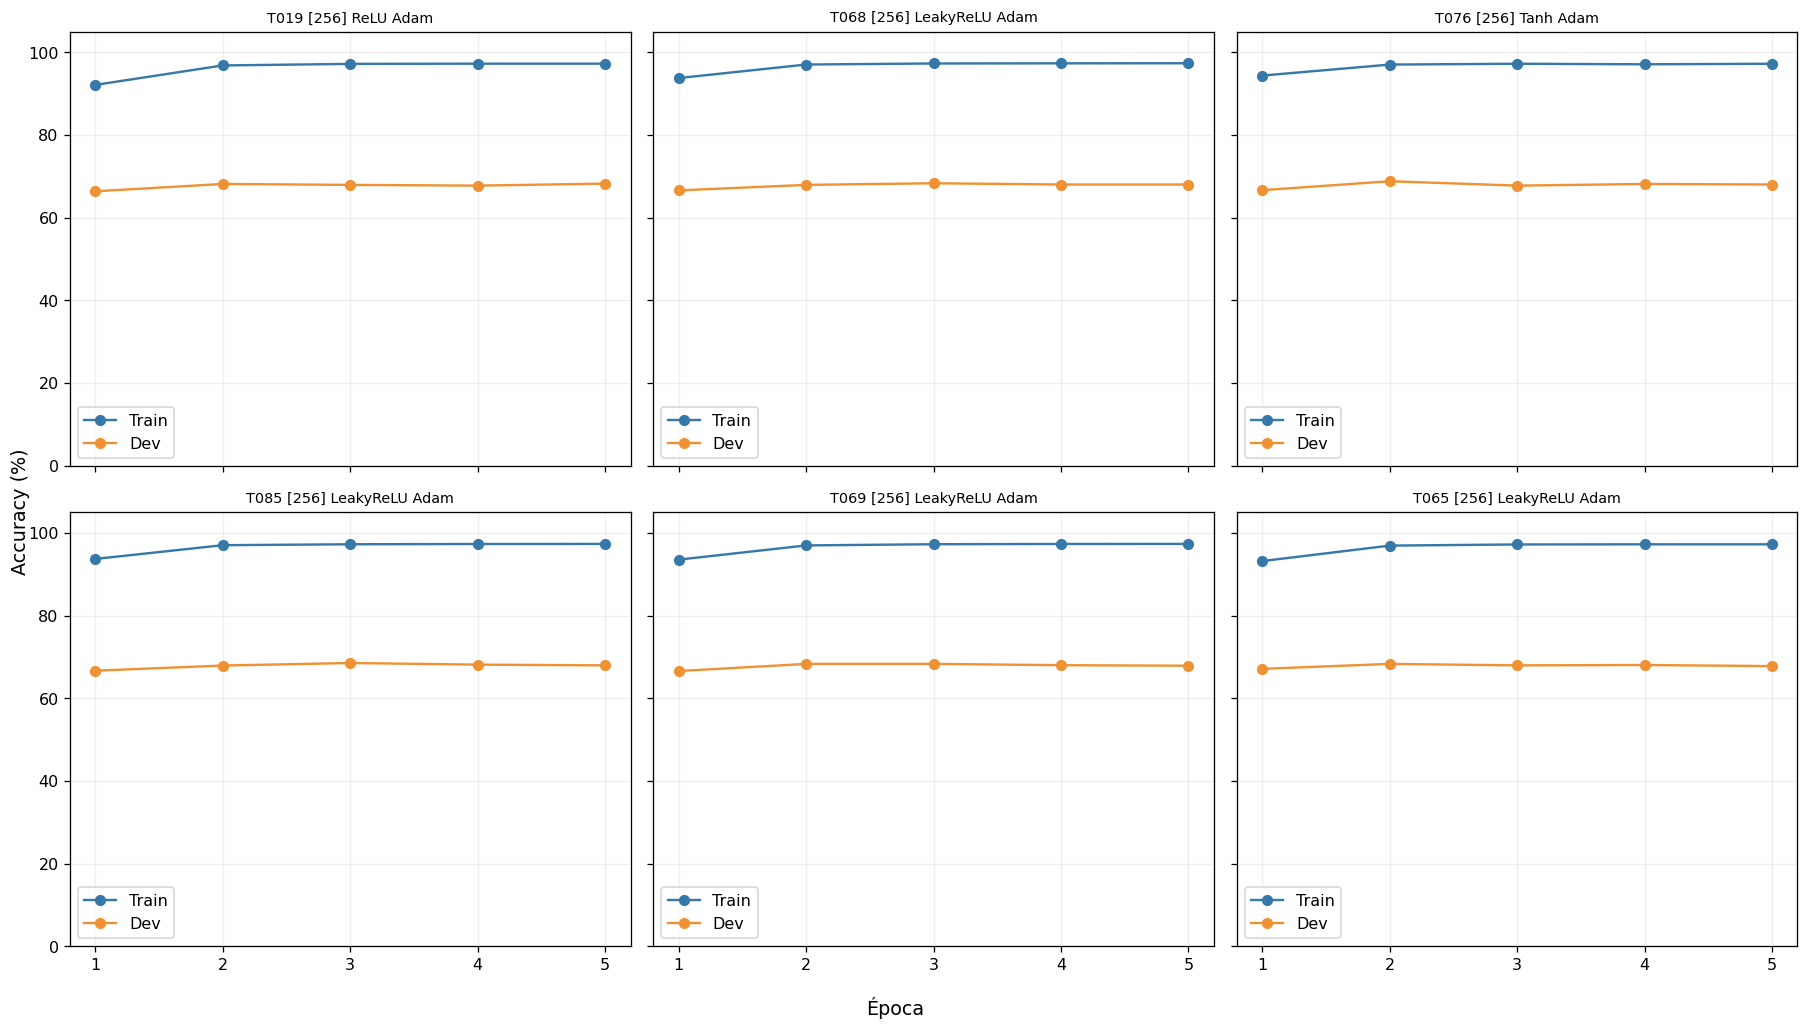

In [20]:
selectedModel = bestModelBundle["model"]
selectedParameters = bestModelBundle["parameters"]
print("Hiperparámetros seleccionados:", selectedParameters)
print(f"Accuracy dev: {bestModelBundle['validationAccuracy']:.2%}")
curveFigure, curveAxes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
topTrialNumbers = completedTable.nlargest(6, "validationAccuracy").trial.tolist()
for curveAxis, trialNumber in zip(curveAxes.flat, topTrialNumbers):
    historyTable = pd.DataFrame(trainingRecords[trialNumber]["history"])
    parameters = trainingRecords[trialNumber]["parameters"]
    curveAxis.plot(historyTable.epoch, 100*historyTable.trainAccuracy, marker="o", label="Train", color="#3678a8")
    curveAxis.plot(historyTable.epoch, 100*historyTable.validationAccuracy, marker="o", label="Dev", color="#ef9234")
    curveAxis.set_title(f"T{trialNumber:03d} {parameters['hiddenWidths']} {parameters['activationName']} {parameters['optimizerName']}", fontsize=9)
    curveAxis.set_ylim(0, 105)
    curveAxis.set_xticks(range(1, EPOCH_COUNT+1))
    curveAxis.legend()
for curveAxis in list(curveAxes.flat)[len(topTrialNumbers):]:
    curveAxis.set_visible(False)
curveFigure.supxlabel("Época")
curveFigure.supylabel("Accuracy (%)")
curveFigure.tight_layout()
plt.show()

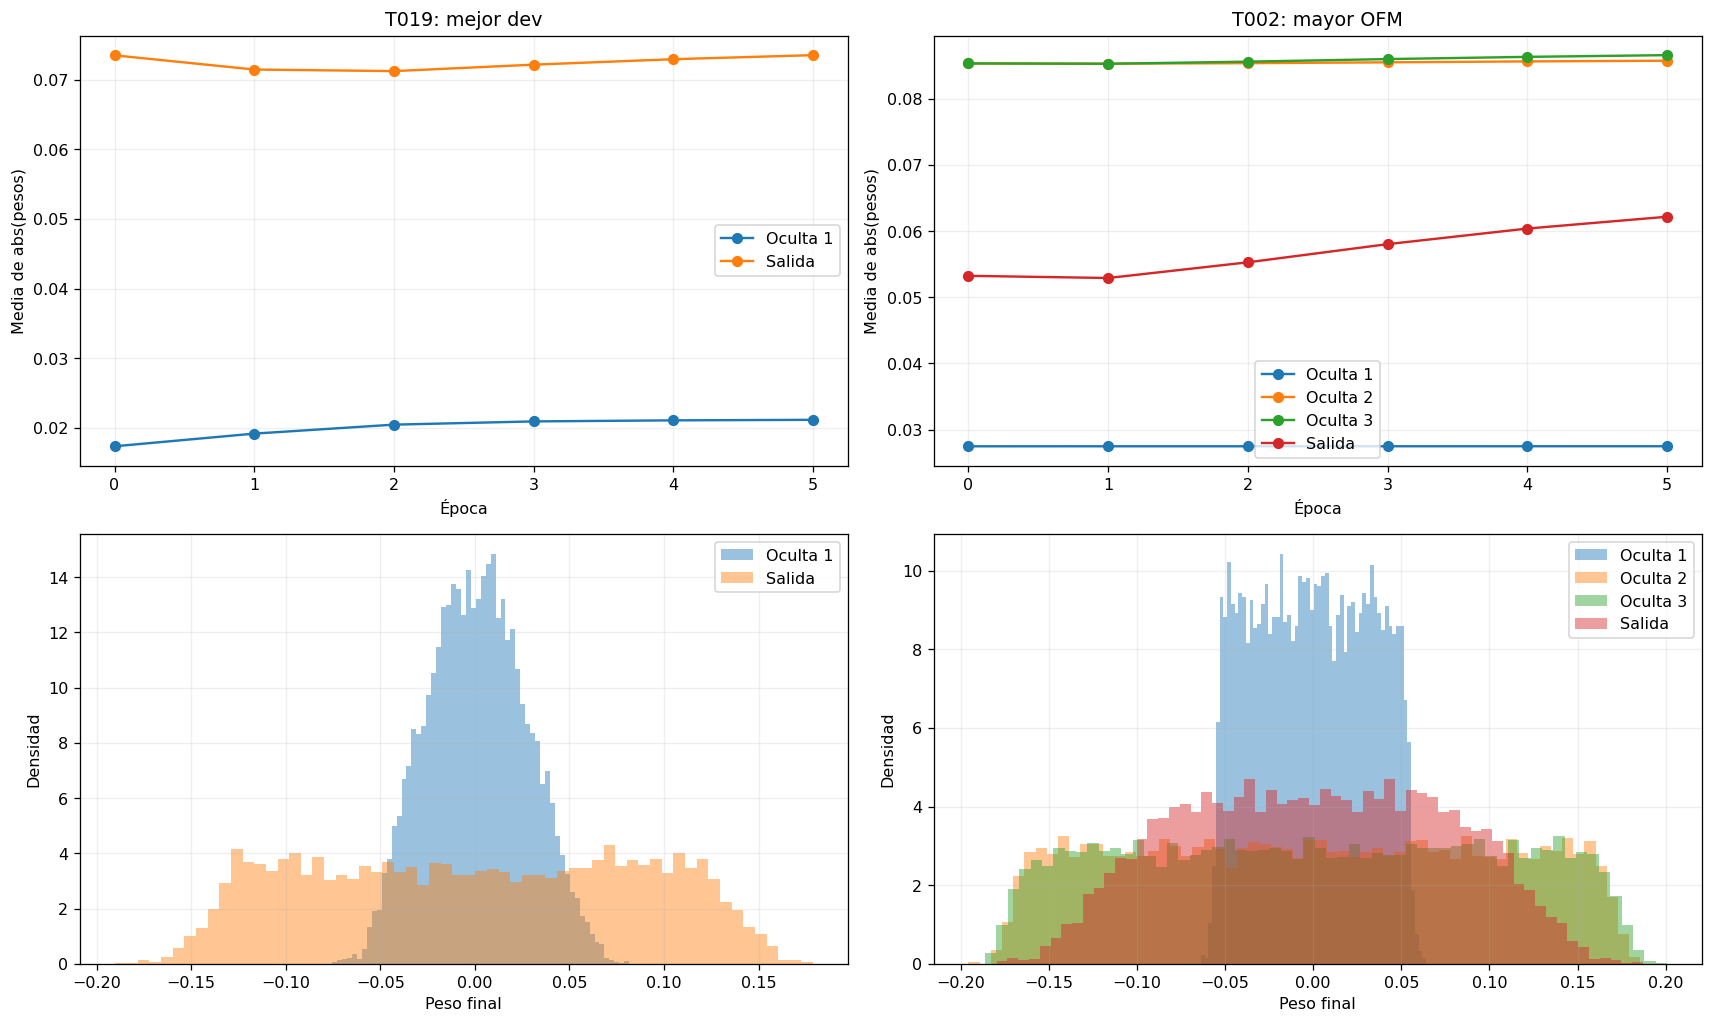

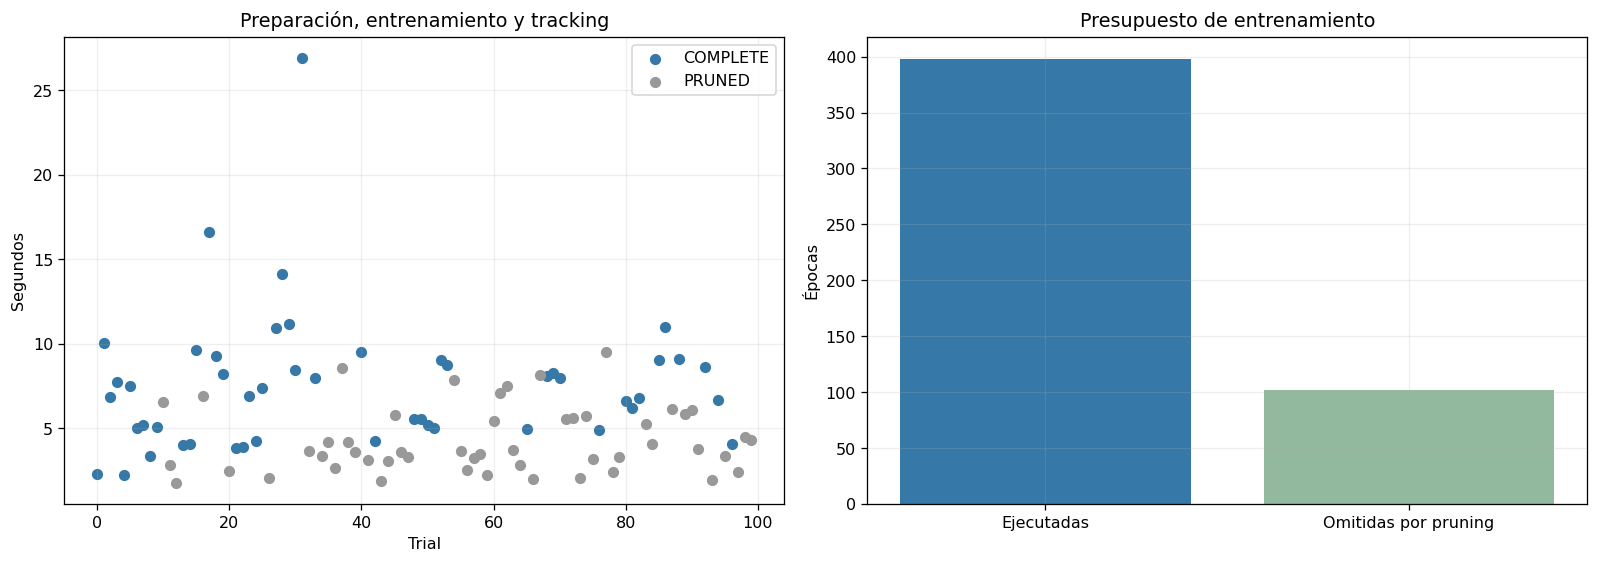

In [21]:
weightFigure, weightAxes = plt.subplots(2, 2, figsize=(15, 9))
for columnIndex, trialNumber in enumerate([bestTrialNumber, maximumGapTrialNumber]):
    record = trainingRecords[trialNumber]
    weightTable = pd.DataFrame(record["weightHistory"])
    weightColumns = list(weightTable.columns.drop("epoch"))
    for layerIndex, parameterName in enumerate(weightColumns):
        layerLabel = "Salida" if layerIndex == len(weightColumns)-1 else f"Oculta {layerIndex+1}"
        weightAxes[0, columnIndex].plot(weightTable.epoch, weightTable[parameterName], marker="o", label=layerLabel)
        weightAxes[1, columnIndex].hist(record["finalWeightSamples"][parameterName], bins=60,
            density=True, alpha=0.45, label=layerLabel)
    weightAxes[0, columnIndex].set(title=f"T{trialNumber:03d}: {'mejor dev' if columnIndex==0 else 'mayor OFM'}",
                                  xlabel="Época", ylabel="Media de abs(pesos)")
    weightAxes[1, columnIndex].set(xlabel="Peso final", ylabel="Densidad")
    weightAxes[0, columnIndex].legend()
    weightAxes[1, columnIndex].legend()
weightFigure.tight_layout()
plt.show()

timeFigure, timeAxes = plt.subplots(1, 2, figsize=(14, 5))
for trialState, trialColor in [("COMPLETE", "#3678a8"), ("PRUNED", "#999999")]:
    stateTable = summaryTable[summaryTable.state == trialState]
    timeAxes[0].scatter(stateTable.trial, stateTable.totalSeconds, label=trialState, color=trialColor)
timeAxes[0].set(xlabel="Trial", ylabel="Segundos", title="Preparación, entrenamiento y tracking")
timeAxes[0].legend()
timeAxes[1].bar(["Ejecutadas", "Omitidas por pruning"], [executedEpochs, omittedEpochs], color=["#3678a8", "#92b99e"])
timeAxes[1].set(ylabel="Épocas", title="Presupuesto de entrenamiento")
timeFigure.tight_layout()
plt.show()

### 7.1. Evaluación del modelo seleccionado en dev

Las métricas por clase complementan la accuracy de selección. La matriz de confusión corresponde a dev, no al test reservado.

                          precision    recall  f1-score   support

             alt.atheism       0.62      0.49      0.55        96
           comp.graphics       0.69      0.74      0.71       117
 comp.os.ms-windows.misc       0.64      0.55      0.59       118
comp.sys.ibm.pc.hardware       0.57      0.62      0.59       118
   comp.sys.mac.hardware       0.71      0.67      0.69       115
          comp.windows.x       0.76      0.66      0.71       119
            misc.forsale       0.62      0.60      0.61       117
               rec.autos       0.45      0.67      0.54       119
         rec.motorcycles       0.73      0.64      0.68       120
      rec.sport.baseball       0.78      0.82      0.80       119
        rec.sport.hockey       0.90      0.86      0.88       120
               sci.crypt       0.78      0.73      0.76       119
         sci.electronics       0.69      0.71      0.70       118
                 sci.med       0.82      0.82      0.82       119
         

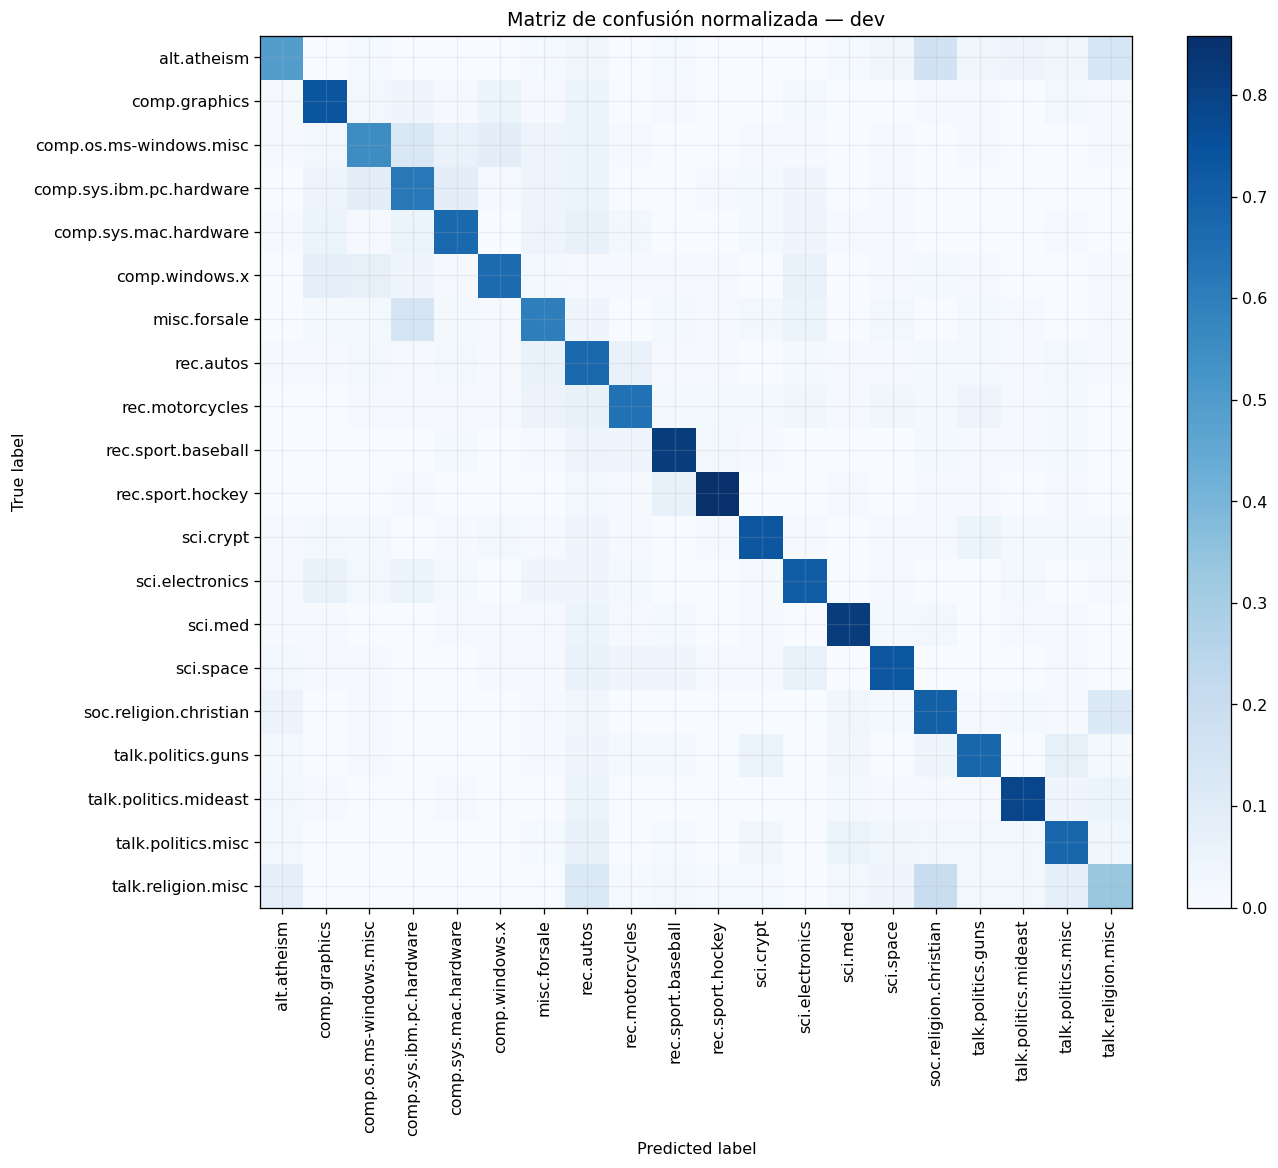

In [22]:
selectedValidationPredictions = bestModelBundle["validationPredictions"]
assert np.isclose(accuracy_score(validationLabels, selectedValidationPredictions), study.best_value)
print(classification_report(validationLabels, selectedValidationPredictions, target_names=classNames, zero_division=0))
confusionFigure, confusionAxis = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(validationLabels, selectedValidationPredictions,
    display_labels=classNames, normalize="true", cmap="Blues", xticks_rotation=90, ax=confusionAxis,
    include_values=False)
confusionAxis.set_title("Matriz de confusión normalizada — dev")
confusionFigure.tight_layout()
plt.show()
with mlflow.start_run(run_name=f"{studyLabel}_modelo_seleccionado"):
    mlflow.set_tag("study", studyLabel)
    mlflow.log_params(selectedParameters)
    mlflow.log_metric("validationAccuracy", study.best_value)
    mlflow.log_figure(curveFigure, "curvas.png")
    mlflow.log_figure(weightFigure, "pesos.png")
    mlflow.log_figure(timeFigure, "tiempos.png")
    mlflow.log_figure(confusionFigure, "confusion_dev.png")

savedMlpFiles = bestModelBundle["savedFiles"]

### 7.2. Regresión Softmax: búsqueda y modelo seleccionado

Softmax se entrena en este notebook mediante el mismo procedimiento de evaluación y tracking del MLP. Tiene un presupuesto independiente de 100 trials de hasta cinco épocas, el mismo espacio común de hiperparámetros y las mismas particiones. La comparación corresponde a pipelines seleccionados por dev, con igual presupuesto de búsqueda; no permite atribuir todas las diferencias exclusivamente a la arquitectura.

In [23]:
softmaxStudy, softmaxTrainingRecords, softmaxBestModelBundle, softmaxSearchSeconds = runModelSearch(
    "Softmax", SOFTMAX_TRIAL_COUNT)
softmaxSummaryTable = summarizeTrainingRecords("Softmax", softmaxTrainingRecords)
softmaxCompletedTable = softmaxSummaryTable[softmaxSummaryTable.state == "COMPLETE"].copy()
print(f"Softmax: completos {len(softmaxCompletedTable)} | podados {(softmaxSummaryTable.state == 'PRUNED').sum()}")
print("Hiperparametros seleccionados:", softmaxBestModelBundle["parameters"])
print(f"Accuracy dev Softmax: {softmaxBestModelBundle['validationAccuracy']:.2%}")
display(softmaxCompletedTable.nlargest(10, "validationAccuracy").style.format({
    "trainAccuracy": "{:.2%}", "validationAccuracy": "{:.2%}", "maximumGap": "{:.2%}", "learningRate": "{:.6f}"}))
savedSoftmaxFiles = softmaxBestModelBundle["savedFiles"]
selectedModelBundles = {"MLP": bestModelBundle, "Softmax": softmaxBestModelBundle}
allSummaryTable = pd.concat([summaryTable, softmaxSummaryTable], ignore_index=True)

Softmax | Trial 000 | COMPLETE | épocas 5 | dev 55.06%
Softmax | Trial 001 | COMPLETE | épocas 5 | dev 64.69%
Softmax | Trial 002 | COMPLETE | épocas 5 | dev 61.03%
Softmax | Trial 003 | COMPLETE | épocas 5 | dev 59.88%
Softmax | Trial 004 | COMPLETE | épocas 5 | dev 59.52%
Softmax | Trial 005 | COMPLETE | épocas 5 | dev 54.84%
Softmax | Trial 006 | COMPLETE | épocas 5 | dev 59.08%
Softmax | Trial 007 | COMPLETE | épocas 5 | dev 49.54%
Softmax | Trial 008 | COMPLETE | épocas 5 | dev 52.05%
Softmax | Trial 009 | COMPLETE | épocas 5 | dev 55.99%
Softmax | Trial 010 | COMPLETE | épocas 5 | dev 64.38%
Softmax | Trial 011 | PRUNED | épocas 3 | dev 9.59%
Softmax | Trial 012 | COMPLETE | épocas 5 | dev 64.60%
Softmax | Trial 013 | PRUNED | épocas 3 | dev 24.26%
Softmax | Trial 014 | COMPLETE | épocas 5 | dev 63.94%
Softmax | Trial 015 | COMPLETE | épocas 5 | dev 60.85%
Softmax | Trial 016 | PRUNED | épocas 3 | dev 33.10%
Softmax | Trial 017 | PRUNED | épocas 3 | dev 25.19%
Softmax | Trial 018

,modelFamily,trial,state,epochs,hiddenLayerCount,hiddenWidths,activation,optimizer,learningRate,trainAccuracy,validationAccuracy,maximumGap,maximumGapEpoch,totalSeconds,trainingSeconds
70,Softmax,70,COMPLETE,5,0,[],Lineal,Adam,0.002149,97.08%,67.70%,29.39%,5,5.100319,1.636864
71,Softmax,71,COMPLETE,5,0,[],Lineal,Adam,0.002312,97.11%,67.61%,29.50%,5,5.327186,1.690963
68,Softmax,68,COMPLETE,5,0,[],Lineal,Adam,0.002324,97.11%,67.57%,29.54%,5,5.363567,1.715846
75,Softmax,75,COMPLETE,5,0,[],Lineal,Adam,0.002564,97.13%,67.52%,29.61%,5,8.589249,3.849979
66,Softmax,66,COMPLETE,5,0,[],Lineal,Adam,0.002507,97.11%,67.48%,29.63%,5,7.354644,1.662474
73,Softmax,73,COMPLETE,5,0,[],Lineal,Adam,0.002592,97.16%,67.48%,29.68%,5,4.924739,1.471607
91,Softmax,91,COMPLETE,5,0,[],Lineal,Adam,0.002736,97.20%,67.48%,29.73%,5,10.231604,3.778047
38,Softmax,38,COMPLETE,5,0,[],Lineal,Adam,0.001709,97.23%,67.39%,29.99%,4,3.199218,1.699071
65,Softmax,65,COMPLETE,5,0,[],Lineal,Adam,0.002816,97.23%,67.30%,29.93%,5,10.505659,3.805054
74,Softmax,74,COMPLETE,5,0,[],Lineal,Adam,0.003038,97.22%,67.30%,29.92%,5,4.924697,1.437610


                          precision    recall  f1-score   support

             alt.atheism       0.73      0.61      0.67        96
           comp.graphics       0.59      0.62      0.61       117
 comp.os.ms-windows.misc       0.67      0.53      0.59       118
comp.sys.ibm.pc.hardware       0.57      0.60      0.58       118
   comp.sys.mac.hardware       0.60      0.57      0.58       115
          comp.windows.x       0.72      0.68      0.70       119
            misc.forsale       0.68      0.68      0.68       117
               rec.autos       0.40      0.66      0.50       119
         rec.motorcycles       0.70      0.58      0.64       120
      rec.sport.baseball       0.83      0.78      0.81       119
        rec.sport.hockey       0.82      0.85      0.83       120
               sci.crypt       0.85      0.71      0.78       119
         sci.electronics       0.74      0.71      0.73       118
                 sci.med       0.76      0.89      0.82       119
         

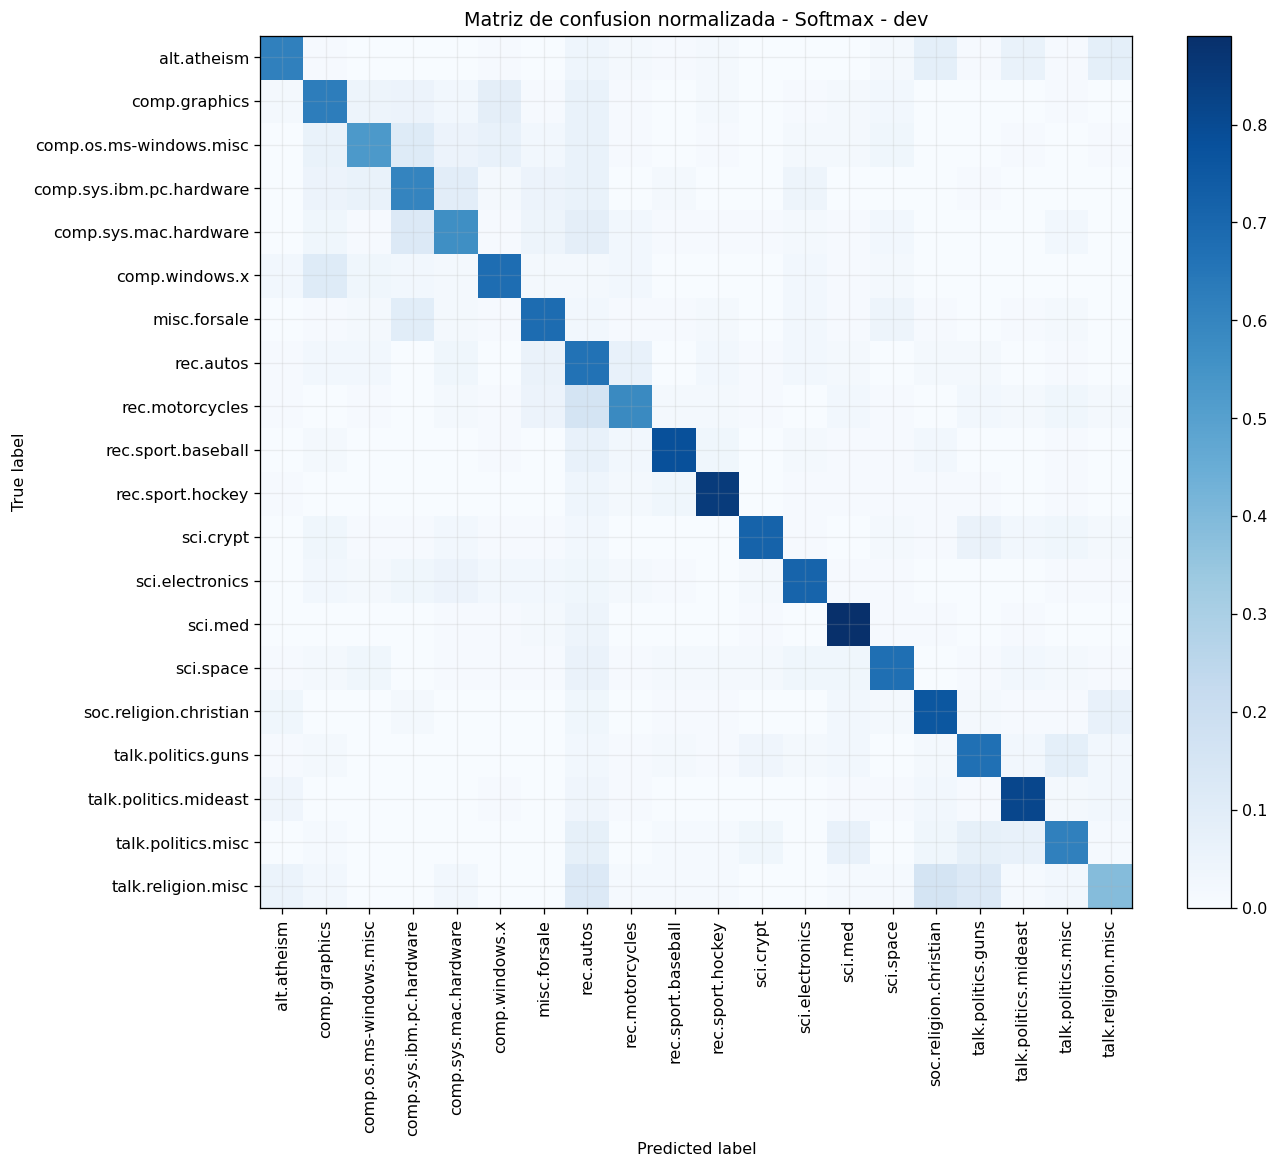

In [24]:
softmaxValidationPredictions = softmaxBestModelBundle["validationPredictions"]
assert np.isclose(accuracy_score(validationLabels, softmaxValidationPredictions), softmaxStudy.best_value)
print(classification_report(validationLabels, softmaxValidationPredictions, target_names=classNames, zero_division=0))
softmaxConfusionFigure, softmaxConfusionAxis = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(validationLabels, softmaxValidationPredictions,
    display_labels=classNames, normalize="true", cmap="Blues", xticks_rotation=90,
    ax=softmaxConfusionAxis, include_values=False)
softmaxConfusionAxis.set_title("Matriz de confusion normalizada - Softmax - dev")
softmaxConfusionFigure.tight_layout()
plt.show()
with mlflow.start_run(run_name=f"{studyLabel}_Softmax_evaluacion_dev"):
    mlflow.set_tags({"study": studyLabel, "modelFamily": "Softmax"})
    mlflow.log_metric("validationAccuracy", softmaxStudy.best_value)
    mlflow.log_figure(softmaxConfusionFigure, "confusion_dev.png")

## 8. Evaluación final en test

El test oficial queda reservado. Su evaluación está desactivada durante la búsqueda y requiere cerrar previamente la selección del modelo. No interviene en el pruning ni en la selección de hiperparámetros.

MLP | Accuracy test: 60.55% | Loss test: 1.9488
                          precision    recall  f1-score   support

             alt.atheism       0.43      0.37      0.40       319
           comp.graphics       0.55      0.58      0.57       389
 comp.os.ms-windows.misc       0.53      0.51      0.52       394
comp.sys.ibm.pc.hardware       0.51      0.55      0.53       392
   comp.sys.mac.hardware       0.66      0.61      0.63       385
          comp.windows.x       0.74      0.58      0.65       395
            misc.forsale       0.65      0.69      0.67       390
               rec.autos       0.42      0.64      0.51       396
         rec.motorcycles       0.69      0.61      0.65       398
      rec.sport.baseball       0.81      0.74      0.78       397
        rec.sport.hockey       0.87      0.84      0.86       399
               sci.crypt       0.73      0.68      0.70       396
         sci.electronics       0.53      0.52      0.53       393
                 sci.med   

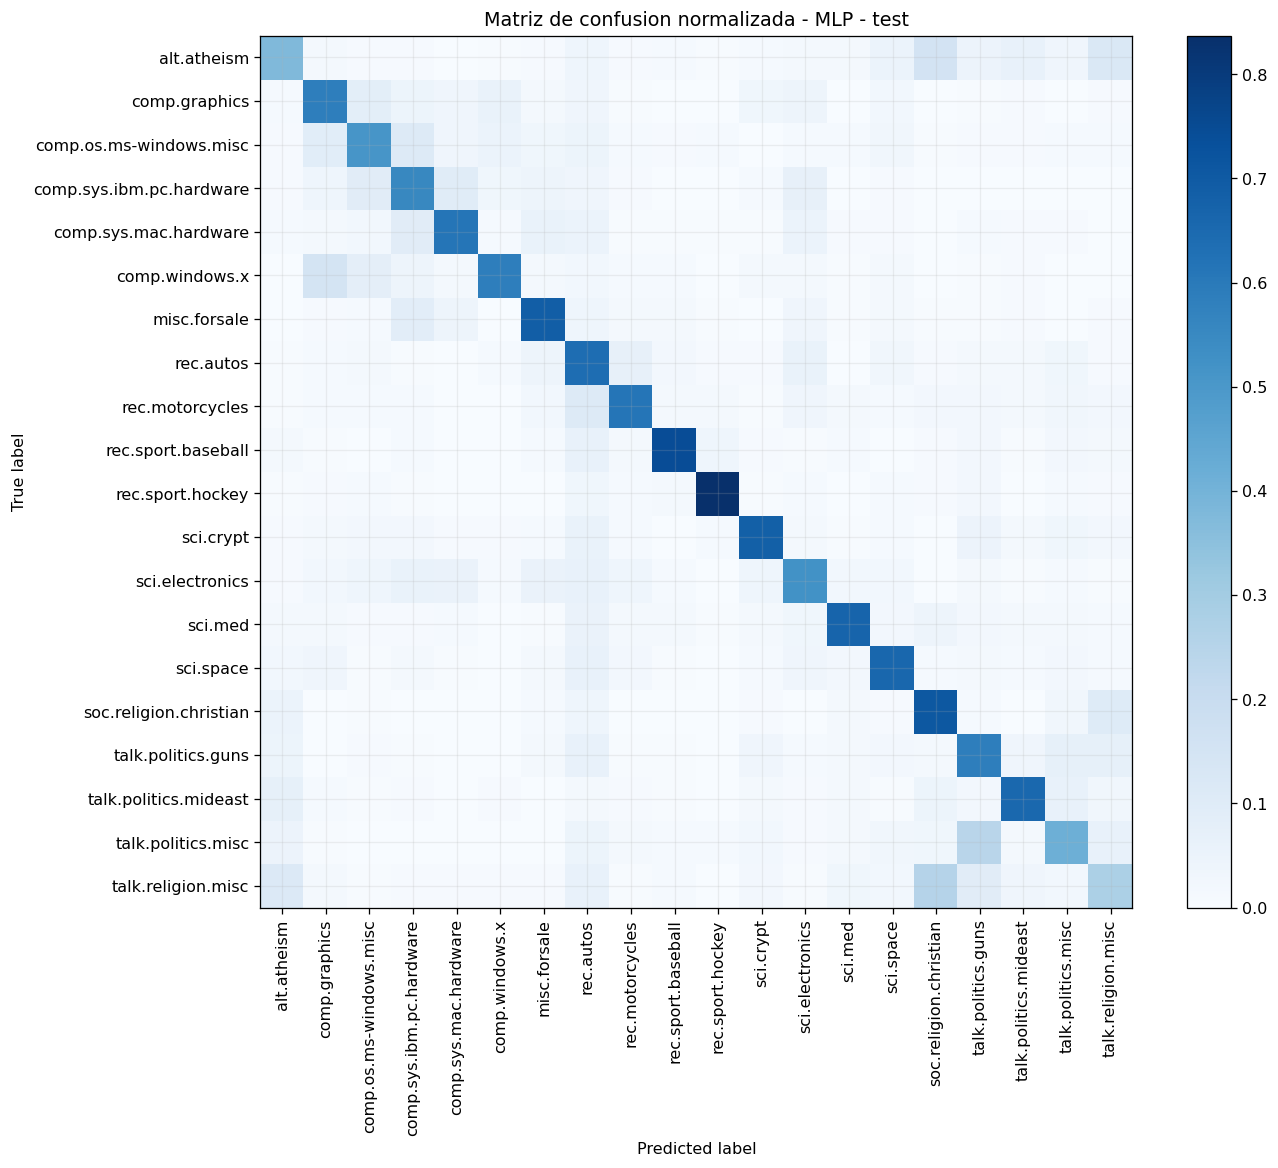

Softmax | Accuracy test: 58.48% | Loss test: 1.9924
                          precision    recall  f1-score   support

             alt.atheism       0.47      0.39      0.42       319
           comp.graphics       0.55      0.53      0.54       389
 comp.os.ms-windows.misc       0.52      0.45      0.48       394
comp.sys.ibm.pc.hardware       0.54      0.55      0.54       392
   comp.sys.mac.hardware       0.58      0.58      0.58       385
          comp.windows.x       0.70      0.61      0.65       395
            misc.forsale       0.69      0.67      0.68       390
               rec.autos       0.39      0.66      0.49       396
         rec.motorcycles       0.60      0.49      0.54       398
      rec.sport.baseball       0.78      0.68      0.72       397
        rec.sport.hockey       0.82      0.82      0.82       399
               sci.crypt       0.70      0.63      0.66       396
         sci.electronics       0.54      0.50      0.52       393
                 sci.me

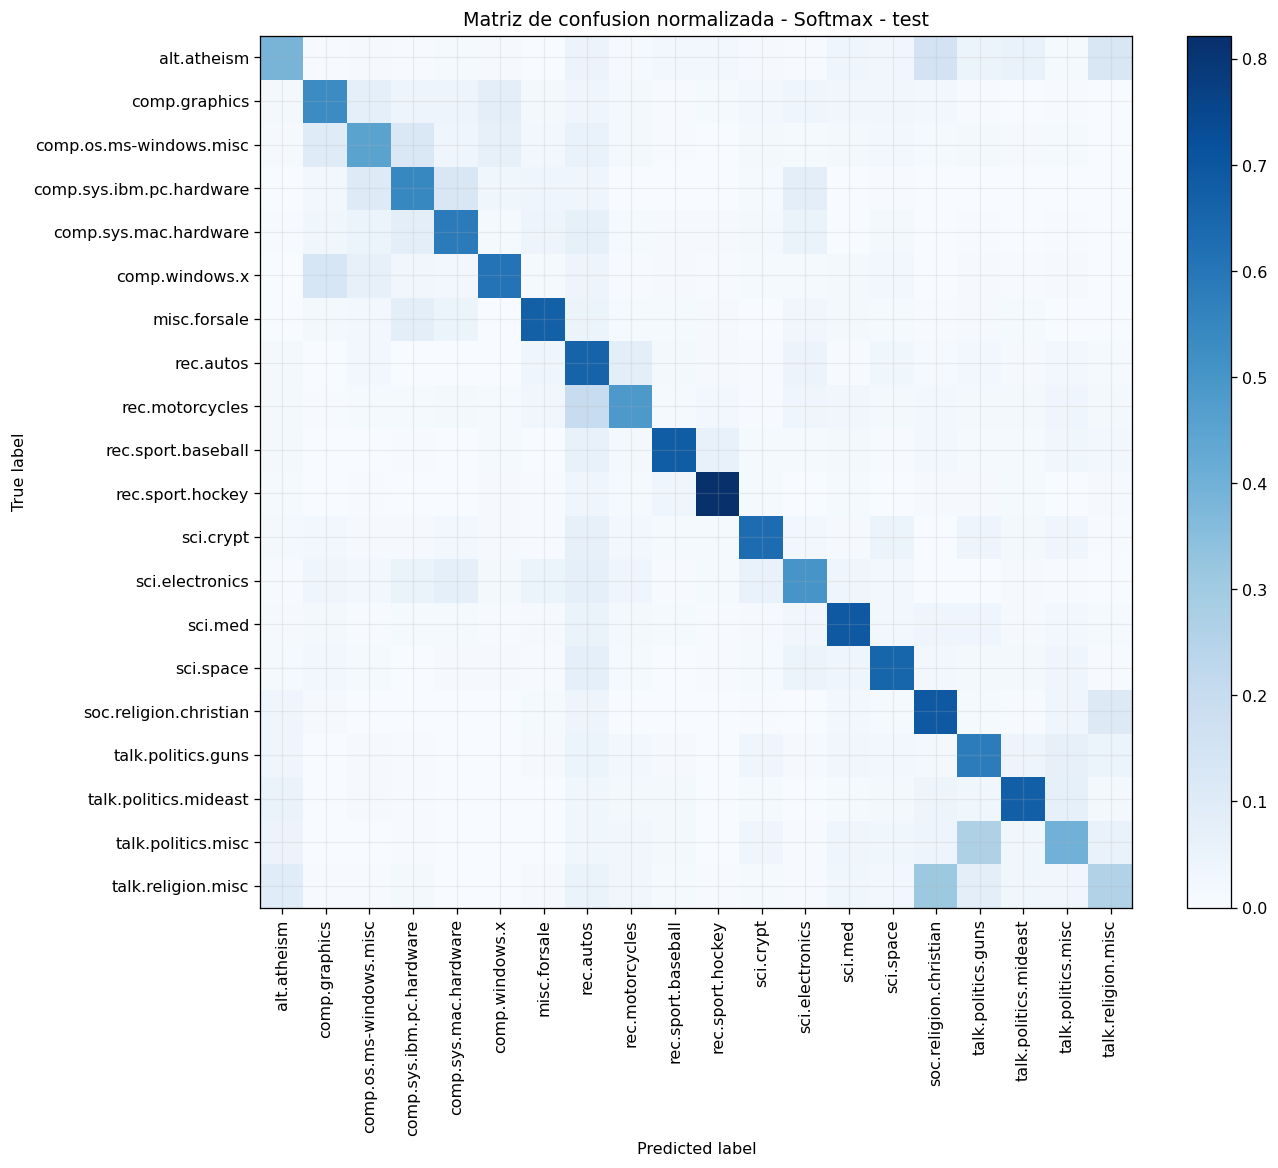

In [32]:
if EVALUATE_TEST:
    officialTestDataset = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))
    for modelFamily, modelBundle in selectedModelBundles.items():
        parameters = modelBundle["parameters"]
        selectedTestDocuments = [preprocessText(document, parameters["removeStopwords"],
            parameters["textNormalization"]) for document in officialTestDataset.data]
        selectedTestFeatures = modelBundle["vectorizer"].transform(selectedTestDocuments).toarray().astype(np.float32)
        selectedTestFeatures = modelBundle["scaler"].transform(selectedTestFeatures)
        selectedTestLoader = DataLoader(TensorDataset(torch.from_numpy(selectedTestFeatures),
            torch.as_tensor(officialTestDataset.target, dtype=torch.long)), batch_size=512, shuffle=False)
        testLoss, testAccuracy = evaluateModel(modelBundle["model"], selectedTestLoader)
        testPredictions = predictModel(modelBundle["model"], selectedTestLoader)
        print(f"{modelFamily} | Accuracy test: {testAccuracy:.2%} | Loss test: {testLoss:.4f}")
        print(classification_report(officialTestDataset.target, testPredictions,
            target_names=classNames, zero_division=0))
        testFigure, testAxis = plt.subplots(figsize=(12, 10))
        ConfusionMatrixDisplay.from_predictions(officialTestDataset.target, testPredictions,
            display_labels=classNames, normalize="true", cmap="Blues", xticks_rotation=90,
            ax=testAxis, include_values=False)
        testAxis.set_title(f"Matriz de confusion normalizada - {modelFamily} - test")
        testFigure.tight_layout()
        plt.show()
        with mlflow.start_run(run_name=f"{studyLabel}_{modelFamily}_evaluacion_test"):
            mlflow.set_tags({"study": studyLabel, "modelFamily": modelFamily})
            mlflow.log_metrics({"testAccuracy": testAccuracy, "testLoss": testLoss})
            mlflow.log_figure(testFigure, "confusion_test.png")
else:
    print("Test reservado: no evaluado.")

## 9. Comparación de resultados

Se comparan los modelos completos seleccionados mediante accuracy de dev. Ambos se entrenan con 9.051 documentos durante cinco épocas y sus transformaciones se ajustan exclusivamente con train. La comparación incluye accuracy, loss, OFM y tiempos. No corresponde a la evaluación final en test.

,trial,trials,completeTrials,prunedTrials,parameterCount,trainAccuracy,validationAccuracy,accuracyGap,trainLoss,validationLoss,trainingSeconds,searchSeconds
modelFamily,,,,,,,,,,,,
MLP,19,100,49,51,1285396,97.26%,68.23%,29.03%,0.0939,1.5186,6.07,629.1
Softmax,70,100,61,39,200020,97.08%,67.70%,29.39%,0.1119,1.4422,1.64,545.1


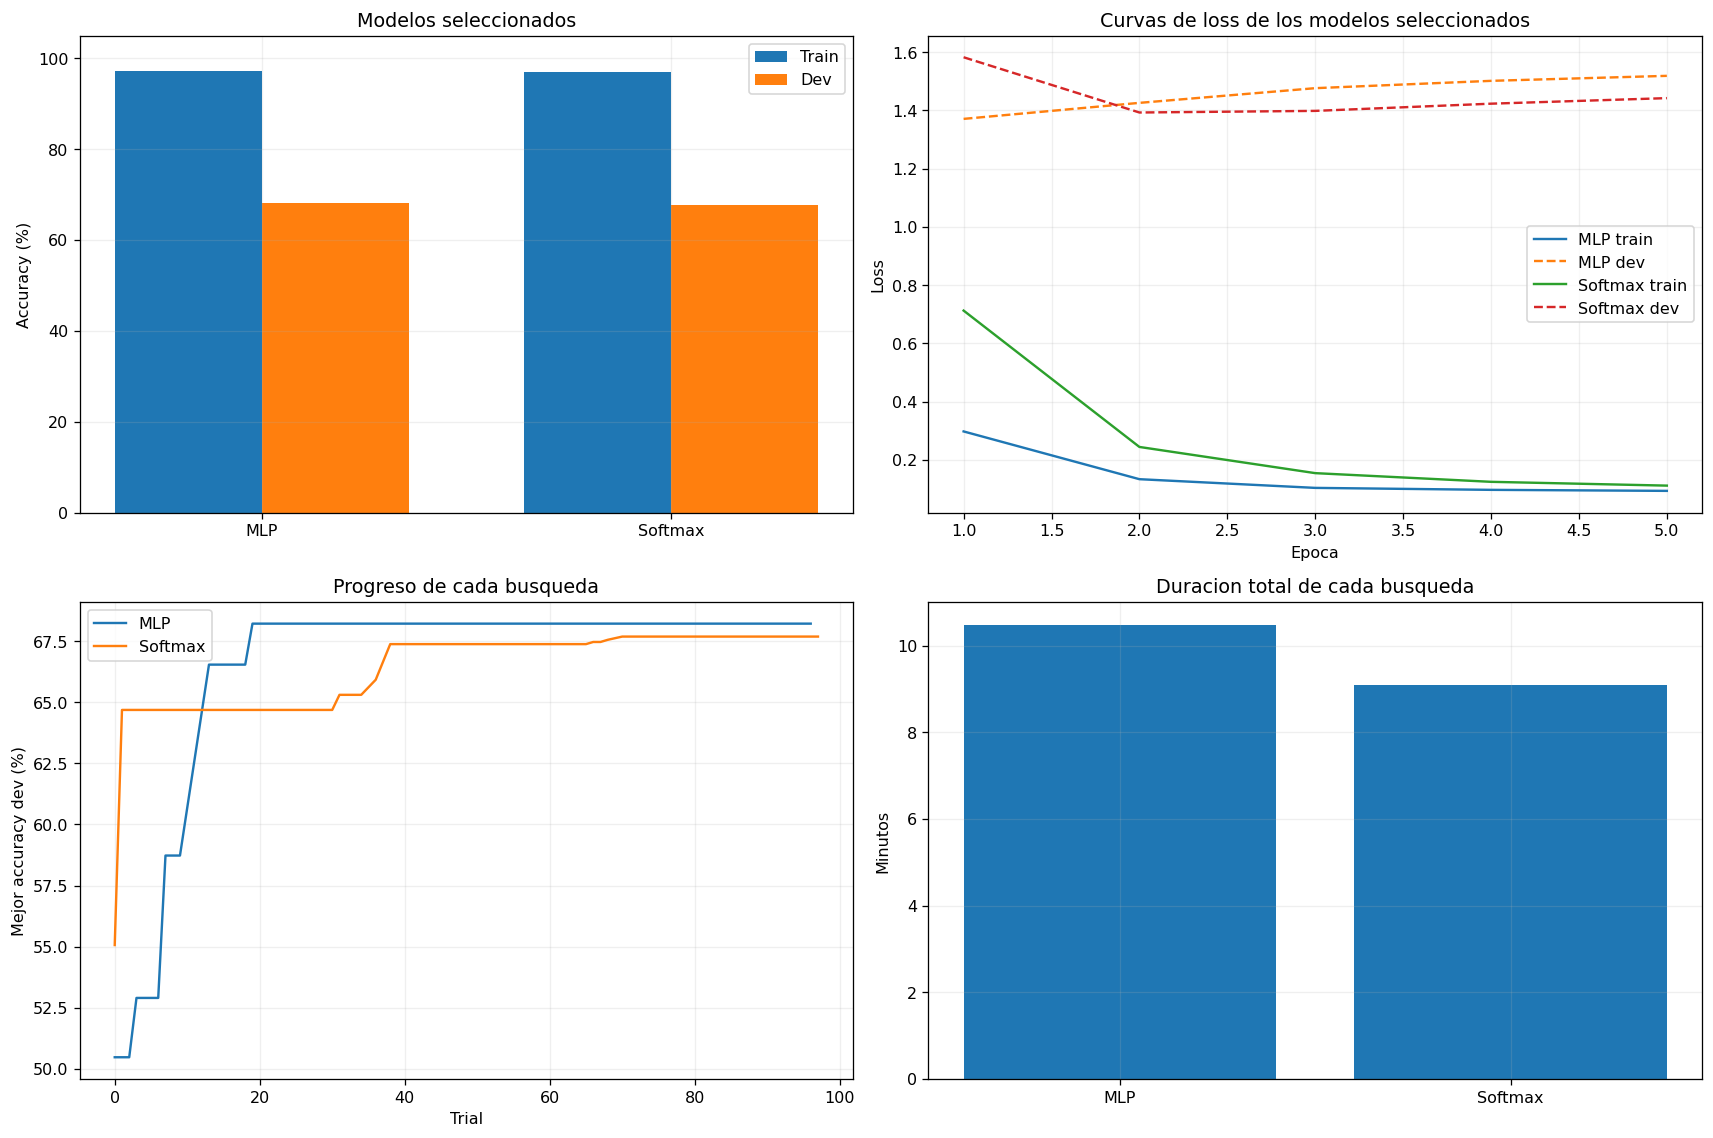

In [26]:
modelRecords = {"MLP": trainingRecords, "Softmax": softmaxTrainingRecords}
modelSearchSeconds = {"MLP": searchSeconds, "Softmax": softmaxSearchSeconds}
modelBudgets = {"MLP": MLP_TRIAL_COUNT, "Softmax": SOFTMAX_TRIAL_COUNT}
modelComparisonRows = []
for modelFamily, modelBundle in selectedModelBundles.items():
    record = modelRecords[modelFamily][modelBundle["trial"]]
    lastEpoch = record["history"][-1]
    familyTable = allSummaryTable[allSummaryTable.modelFamily == modelFamily]
    modelComparisonRows.append({"modelFamily": modelFamily, "trial": modelBundle["trial"],
        "trials": len(modelRecords[modelFamily]), "completeTrials": int((familyTable.state == "COMPLETE").sum()),
        "prunedTrials": int((familyTable.state == "PRUNED").sum()), "parameterCount": record["parameterCount"],
        "trainAccuracy": lastEpoch["trainAccuracy"], "validationAccuracy": lastEpoch["validationAccuracy"],
        "accuracyGap": lastEpoch["accuracyGap"], "trainLoss": lastEpoch["trainLoss"],
        "validationLoss": lastEpoch["validationLoss"], "trainingSeconds": record["trainingSeconds"],
        "searchSeconds": modelSearchSeconds[modelFamily]})
modelComparisonTable = pd.DataFrame(modelComparisonRows).set_index("modelFamily")
display(modelComparisonTable.style.format({"trainAccuracy": "{:.2%}", "validationAccuracy": "{:.2%}",
    "accuracyGap": "{:.2%}", "trainLoss": "{:.4f}", "validationLoss": "{:.4f}",
    "trainingSeconds": "{:.2f}", "searchSeconds": "{:.1f}"}))

modelComparisonFigure, modelComparisonAxes = plt.subplots(2, 2, figsize=(15, 10))
accuracyComparisonAxis, lossComparisonAxis, progressComparisonAxis, durationComparisonAxis = modelComparisonAxes.flat
modelNames = modelComparisonTable.index.tolist()
modelPositions = np.arange(len(modelNames))
accuracyComparisonAxis.bar(modelPositions-0.18, 100*modelComparisonTable.trainAccuracy, width=0.36, label="Train")
accuracyComparisonAxis.bar(modelPositions+0.18, 100*modelComparisonTable.validationAccuracy, width=0.36, label="Dev")
accuracyComparisonAxis.set(xticks=modelPositions, xticklabels=modelNames, ylabel="Accuracy (%)", ylim=(0, 105), title="Modelos seleccionados")
accuracyComparisonAxis.legend()
for modelFamily, modelBundle in selectedModelBundles.items():
    selectedHistory = pd.DataFrame(modelRecords[modelFamily][modelBundle["trial"]]["history"])
    lossComparisonAxis.plot(selectedHistory.epoch, selectedHistory.trainLoss, label=f"{modelFamily} train")
    lossComparisonAxis.plot(selectedHistory.epoch, selectedHistory.validationLoss, linestyle="--", label=f"{modelFamily} dev")
    completeFamily = allSummaryTable[(allSummaryTable.modelFamily == modelFamily) & (allSummaryTable.state == "COMPLETE")].sort_values("trial")
    progressComparisonAxis.plot(completeFamily.trial, 100*completeFamily.validationAccuracy.cummax(), label=modelFamily)
lossComparisonAxis.set(xlabel="Epoca", ylabel="Loss", title="Curvas de loss de los modelos seleccionados")
lossComparisonAxis.legend()
progressComparisonAxis.set(xlabel="Trial", ylabel="Mejor accuracy dev (%)", title="Progreso de cada busqueda")
progressComparisonAxis.legend()
durationComparisonAxis.bar(modelNames, modelComparisonTable.searchSeconds/60)
durationComparisonAxis.set(ylabel="Minutos", title="Duracion total de cada busqueda")
modelComparisonFigure.tight_layout()
plt.show()
with mlflow.start_run(run_name=f"{studyLabel}_comparacion_modelos"):
    mlflow.set_tag("study", studyLabel)
    mlflow.log_params({"mlpTrials": MLP_TRIAL_COUNT, "softmaxTrials": SOFTMAX_TRIAL_COUNT,
                       "epochs": EPOCH_COUNT, "seed": SEED, "learningRateMinimum": 0.0001})
    mlflow.log_table(modelComparisonTable.reset_index(), artifact_file="comparacion_modelos.json")
    mlflow.log_figure(modelComparisonFigure, "comparacion_modelos.png")

### 9.1. Resultados por optimizador, activación y cantidad de capas ocultas

Se informa la cantidad de trials completos, podados y fallidos de cada grupo. Las medias, medianas, máximos de accuracy final y tiempos medios de entrenamiento se calculan exclusivamente sobre trials completos. Los optimizadores se agrupan por familia; activación y cantidad de capas se analizan solo para MLP.

TPE concentra la búsqueda en regiones prometedoras y los grupos no tienen igual cantidad de pruebas ni mantienen fijos los demás hiperparámetros. Estos resumenes describen los resultados observados y no establecen efectos causales ni superioridad general de una opción.

Resumen por optimizador


,modelFamily,optimizer,completeTrials,prunedTrials,failedTrials,meanTrainAccuracy,meanDevAccuracy,medianDevAccuracy,bestDevAccuracy,meanTrainingSeconds,meanTotalSeconds
0,MLP,Adam,37,38,0,94.15%,64.55%,66.90%,68.23%,5.93,7.65
1,MLP,RMSprop,10,6,0,79.42%,53.34%,57.95%,66.55%,5.06,6.84
2,MLP,SGD,2,7,0,51.25%,27.09%,27.09%,48.34%,5.42,8.43
3,Softmax,Adam,53,26,0,97.05%,64.64%,65.53%,67.70%,2.14,5.26
4,Softmax,RMSprop,6,5,0,90.24%,57.33%,57.53%,61.91%,1.56,3.57
5,Softmax,SGD,2,8,0,94.93%,62.37%,62.37%,63.72%,1.00,2.22


Resumen por activacion


,activation,completeTrials,prunedTrials,failedTrials,meanTrainAccuracy,meanDevAccuracy,medianDevAccuracy,bestDevAccuracy,meanTrainingSeconds,meanTotalSeconds
0,ELU,7,4,0,93.42%,62.60%,65.36%,66.68%,6.11,7.53
1,LeakyReLU,17,20,0,91.20%,62.60%,66.99%,68.01%,5.07,6.75
2,ReLU,15,22,0,97.03%,66.03%,66.95%,68.23%,7.14,9.05
3,Tanh,10,5,0,72.03%,48.31%,51.02%,68.01%,4.49,6.51


Resumen por capas_ocultas


,hiddenLayerCount,completeTrials,prunedTrials,failedTrials,meanTrainAccuracy,meanDevAccuracy,medianDevAccuracy,bestDevAccuracy,meanTrainingSeconds,meanTotalSeconds
0,1,37,31,0,93.31%,64.12%,66.77%,68.23%,5.69,7.45
1,2,4,9,0,73.86%,49.49%,58.64%,67.26%,2.73,4.28
2,3,8,11,0,79.04%,50.68%,55.81%,67.08%,7.42,9.46


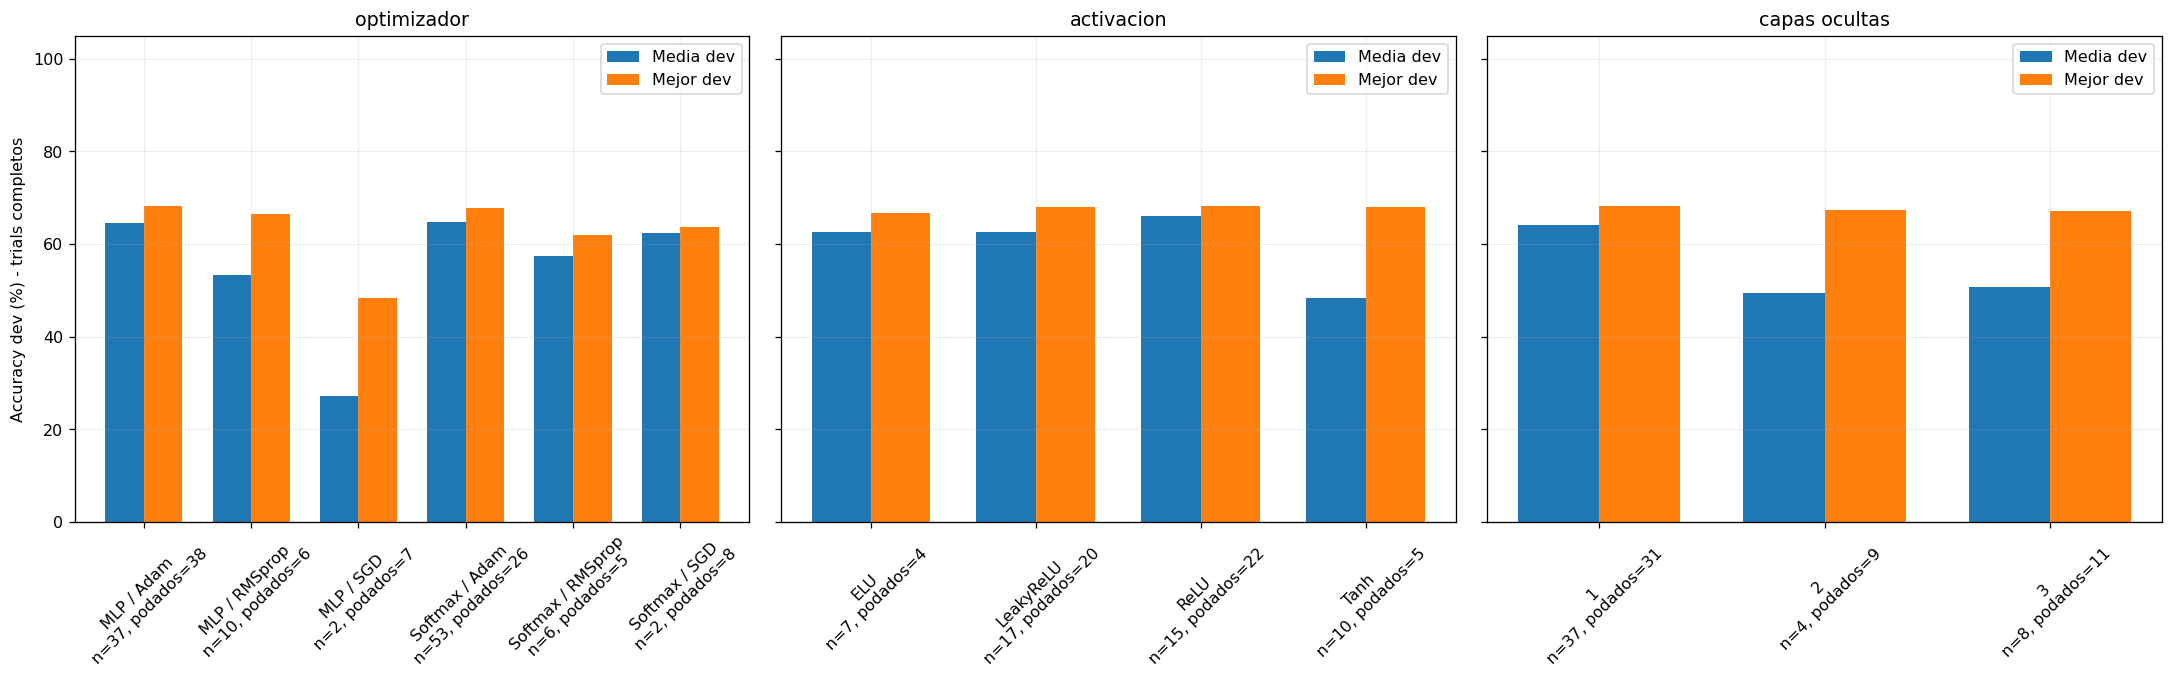

In [33]:
def groupTrialResults(trialTable, groupColumns):
    stateCounts = trialTable.groupby(groupColumns + ["state"], dropna=False).size().unstack("state", fill_value=0)
    stateCounts = stateCounts.reindex(columns=["COMPLETE", "PRUNED", "FAIL"], fill_value=0).rename(
        columns={"COMPLETE": "completeTrials", "PRUNED": "prunedTrials", "FAIL": "failedTrials"})
    completeTrials = trialTable[trialTable.state == "COMPLETE"]
    performance = completeTrials.groupby(groupColumns, dropna=False).agg(
        meanTrainAccuracy=("trainAccuracy", "mean"), meanDevAccuracy=("validationAccuracy", "mean"),
        medianDevAccuracy=("validationAccuracy", "median"), bestDevAccuracy=("validationAccuracy", "max"),
        meanTrainingSeconds=("trainingSeconds", "mean"), meanTotalSeconds=("totalSeconds", "mean"))
    return stateCounts.join(performance).reset_index()

groupedResults = {
    "optimizador": groupTrialResults(allSummaryTable, ["modelFamily", "optimizer"]),
    "activacion": groupTrialResults(summaryTable, ["activation"]),
    "capas_ocultas": groupTrialResults(summaryTable, ["hiddenLayerCount"]),
}
groupFigure, groupAxes = plt.subplots(1, 3, figsize=(19, 6), sharey=True)
for groupAxis, (groupName, groupTable) in zip(groupAxes, groupedResults.items()):
    print(f"Resumen por {groupName}")
    display(groupTable.style.format({"meanTrainAccuracy": "{:.2%}", "meanDevAccuracy": "{:.2%}",
        "medianDevAccuracy": "{:.2%}", "bestDevAccuracy": "{:.2%}",
        "meanTrainingSeconds": "{:.2f}", "meanTotalSeconds": "{:.2f}"}, na_rep="Sin completos"))
    if groupName == "optimizador":
        groupLabels = groupTable.modelFamily + " / " + groupTable.optimizer
    elif groupName == "activacion":
        groupLabels = groupTable.activation.astype(str)
    else:
        groupLabels = groupTable.hiddenLayerCount.astype(str)
    groupLabels = [f"{label}\nn={completeCount}, podados={prunedCount}" for label, completeCount, prunedCount in
                   zip(groupLabels, groupTable.completeTrials, groupTable.prunedTrials)]
    groupPositions = np.arange(len(groupTable))
    groupAxis.bar(groupPositions-0.18, 100*groupTable.meanDevAccuracy, width=0.36, label="Media dev")
    groupAxis.bar(groupPositions+0.18, 100*groupTable.bestDevAccuracy, width=0.36, label="Mejor dev")
    groupAxis.set(xticks=groupPositions, xticklabels=groupLabels, title=groupName.replace("_", " "), ylim=(0, 105))
    groupAxis.tick_params(axis="x", labelrotation=45)
    groupAxis.legend()
groupAxes[0].set_ylabel("Accuracy dev (%) - trials completos")
groupFigure.tight_layout()
plt.show()
with mlflow.start_run(run_name=f"{studyLabel}_resumen_por_hiperparametros"):
    mlflow.set_tag("study", studyLabel)
    for groupName, groupTable in groupedResults.items():
        mlflow.log_table(groupTable, artifact_file=f"resumen_{groupName}.json")
    mlflow.log_figure(groupFigure, "resumen_por_hiperparametros.png")

##10 conclusión
Se realizó la búsqueda de hiperparametros con Optuna TPE y pruning, utilizando 100 trials por modelo y hasta 5 épocas por trial. El MLP seleccionado obtuvo una accuracy de 97,26 % en train, 68,23 % en validación y 60,55 % en test. Softmax obtuvo 67,70 % en validación y 58,48 % en test. Por lo tanto, el MLP logró una mejora de 2,07 puntos porcentuales en test frente al Softmax entrenado en este trabajo. Sin embargo, la diferencia entre train y validación muestra que sigue existiendo overfitting, y el resultado en test confirma que la generalización es la principal limitación del modelo. Dentro del espacio explorado, aumentar la complejidad de la red no garantizó mejores resultados. Como posible mejora se podría incorporar regularización para reducir esta diferencia.